In [8]:
path = '/content/cardiotocography_clean_MSTV.csv'

import pandas as pd
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
plt.style.use('ggplot')
import seaborn as sns

from sklearn.model_selection import train_test_split as tts

from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

from tensorflow.keras.layers import Dropout

from tensorflow.keras.callbacks import EarlyStopping

In [9]:
df = pd.read_csv(path)

df.head()

,b,e,AC,FM,UC,DL,DS,DP,DR,LB,AC.1,FM.1,UC.1,DL.1,DS.1,DP.1,ASTV,MSTV,ALTV,MLTV,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,A,B,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
0,240.0,357.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,2.4,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,-1.0,9.0,2.0
1,5.0,632.0,4.0,0.0,4.0,2.0,0.0,0.0,0.0,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,10.4,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,-1.0,-1.0,6.0,1.0
2,177.0,779.0,2.0,0.0,5.0,2.0,0.0,0.0,0.0,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,13.4,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,-1.0,-1.0,6.0,1.0
3,411.0,1192.0,2.0,0.0,6.0,2.0,0.0,0.0,0.0,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,23.0,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,-1.0,-1.0,6.0,1.0
4,533.0,1147.0,4.0,0.0,5.0,0.0,0.0,0.0,0.0,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,19.9,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,-1.0,1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,2.0,1.0


In [10]:
df.columns

Index(['b', 'e', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'DR', 'LB', 'AC.1',
       'FM.1', 'UC.1', 'DL.1', 'DS.1', 'DP.1', 'ASTV', 'MSTV', 'ALTV', 'MLTV',
       'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median',
       'Variance', 'Tendency', 'A', 'B', 'C', 'D', 'E', 'AD', 'DE', 'LD', 'FS',
       'SUSP', 'CLASS', 'NSP'],
      dtype='object')

In [11]:
df = df[['b', 'e', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'DR', 'LB', 'AC.1',
       'FM.1', 'UC.1', 'DL.1', 'DS.1', 'DP.1', 'ASTV', 'ALTV', 'MLTV',
       'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median',
       'Variance', 'Tendency', 'A', 'B', 'C', 'D', 'E', 'AD', 'DE', 'LD', 'FS',
       'SUSP', 'CLASS', 'NSP', 'MSTV']]

df.head()

,b,e,AC,FM,UC,DL,DS,DP,DR,LB,AC.1,FM.1,UC.1,DL.1,DS.1,DP.1,ASTV,ALTV,MLTV,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,A,B,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP,MSTV
0,240.0,357.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,43.0,2.4,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,-1.0,9.0,2.0,0.5
1,5.0,632.0,4.0,0.0,4.0,2.0,0.0,0.0,0.0,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,0.0,10.4,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,-1.0,-1.0,6.0,1.0,2.1
2,177.0,779.0,2.0,0.0,5.0,2.0,0.0,0.0,0.0,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,0.0,13.4,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,-1.0,-1.0,6.0,1.0,2.1
3,411.0,1192.0,2.0,0.0,6.0,2.0,0.0,0.0,0.0,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,0.0,23.0,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,-1.0,-1.0,6.0,1.0,2.4
4,533.0,1147.0,4.0,0.0,5.0,0.0,0.0,0.0,0.0,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,0.0,19.9,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,-1.0,1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,2.0,1.0,2.4


Tasks

Understand dataset structure

Analyze feature descriptions

Identify numerical variables

Understand physiological significance of fetal monitoring indicators - we can do using correlation

Analyze target variable distribution



In [12]:
df.shape

(2126, 42)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 42 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   b         2126 non-null   float64
 1   e         2126 non-null   float64
 2   AC        2126 non-null   float64
 3   FM        2126 non-null   float64
 4   UC        2126 non-null   float64
 5   DL        2126 non-null   float64
 6   DS        2126 non-null   float64
 7   DP        2126 non-null   float64
 8   DR        2126 non-null   float64
 9   LB        2126 non-null   float64
 10  AC.1      2126 non-null   float64
 11  FM.1      2126 non-null   float64
 12  UC.1      2126 non-null   float64
 13  DL.1      2126 non-null   float64
 14  DS.1      2126 non-null   float64
 15  DP.1      2126 non-null   float64
 16  ASTV      2126 non-null   float64
 17  ALTV      2126 non-null   float64
 18  MLTV      2126 non-null   float64
 19  Width     2126 non-null   float64
 20  Min       2126 non-null   floa

we can see all the features are numerical

#Analyze target variable distribution

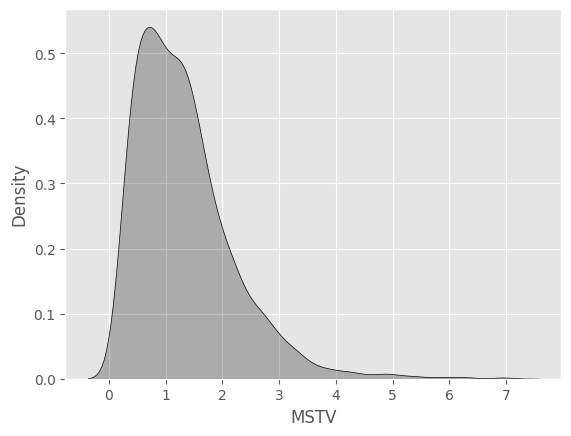

In [16]:
sns.kdeplot(df['MSTV'],fill=True,color='k')
plt.show()

#it looks right skewed

#Phase 2 — Data Cleaning


In [17]:
df.isna().sum()

,0
b,0
e,0
AC,0
FM,0
UC,0
DL,0
DS,0
DP,0
DR,0
LB,0


In [18]:
df.describe()

,b,e,AC,FM,UC,DL,DS,DP,DR,LB,AC.1,FM.1,UC.1,DL.1,DS.1,DP.1,ASTV,ALTV,MLTV,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,A,B,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP,MSTV
count,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.0,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.00000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000
mean,878.439793,1702.877234,2.722484,7.241298,3.659925,1.570085,0.003293,0.126058,0.0,133.303857,0.003170,0.009474,0.004357,0.001885,0.000004,0.000157,46.990122,9.84666,8.187629,70.445908,93.579492,164.025400,4.068203,0.323612,137.452023,134.610536,138.090310,18.808090,0.320320,-0.638758,-0.455315,-0.950141,-0.923801,-0.932267,-0.687676,-0.762935,-0.899341,-0.935089,-0.814675,4.509878,1.304327,1.332785
std,894.084748,930.919143,3.560850,37.125309,2.847094,2.499229,0.057300,0.464361,0.0,9.840844,0.003860,0.046670,0.002940,0.002962,0.000063,0.000580,17.192814,18.39688,5.628247,38.955693,29.560212,17.944183,2.949386,0.706059,16.381289,15.593596,14.466589,28.977636,0.610829,0.769589,0.890540,0.311894,0.382964,0.361856,0.726188,0.646627,0.437350,0.354495,0.580054,3.026883,0.614377,0.883241
min,0.000000,287.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,106.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,12.000000,0.00000,0.000000,3.000000,50.000000,122.000000,0.000000,0.000000,60.000000,73.000000,77.000000,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,1.000000,0.200000
25%,55.000000,1009.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,126.000000,0.000000,0.000000,0.001876,0.000000,0.000000,0.000000,32.000000,0.00000,4.600000,37.000000,67.000000,152.000000,2.000000,0.000000,129.000000,125.000000,129.000000,2.000000,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,2.000000,1.000000,0.700000
50%,538.000000,1241.000000,1.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.0,133.000000,0.001630,0.000000,0.004482,0.000000,0.000000,0.000000,49.000000,0.00000,7.400000,67.500000,93.000000,162.000000,3.000000,0.000000,139.000000,136.000000,139.000000,7.000000,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,4.000000,1.000000,1.200000
75%,1521.000000,2434.750000,4.000000,2.000000,5.000000,3.000000,0.000000,0.000000,0.0,140.000000,0.005631,0.002512,0.006525,0.003264,0.000000,0.000000,61.000000,11.00000,10.800000,100.000000,120.000000,174.000000,6.000000,0.000000,148.000000,145.000000,148.000000,24.000000,1.000000,-1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,7.000000,1.000000,1.700000
max,3296.000000,3599.000000,26.000000,564.000000,23.000000,16.000000,1.000000,4.000000,0.0,160.000000,0.019284,0.480634,0.014925,0.015385,0.001353,0.005348,87.000000,91.00000,50.700000,180.000000,159.000000,238.000000,18.000000,10.000000,187.000000,182.000000,186.000000,269.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,10.000000,3.000000,7.000000


#2.2 Duplicate Handling

In [20]:
df.shape

(2126, 42)

In [21]:
df.duplicated().sum()

np.int64(10)

In [22]:
df.drop_duplicates(inplace=True)

df.shape

# we dropped 10 duplicate rows

(2116, 42)

#2.3 Outlier Detection and Treatment

In [23]:
df.shape

(2116, 42)

In [24]:
num_cols = df.columns[:-1]
num_cols

Index(['b', 'e', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'DR', 'LB', 'AC.1',
       'FM.1', 'UC.1', 'DL.1', 'DS.1', 'DP.1', 'ASTV', 'ALTV', 'MLTV', 'Width',
       'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance',
       'Tendency', 'A', 'B', 'C', 'D', 'E', 'AD', 'DE', 'LD', 'FS', 'SUSP',
       'CLASS', 'NSP'],
      dtype='object')

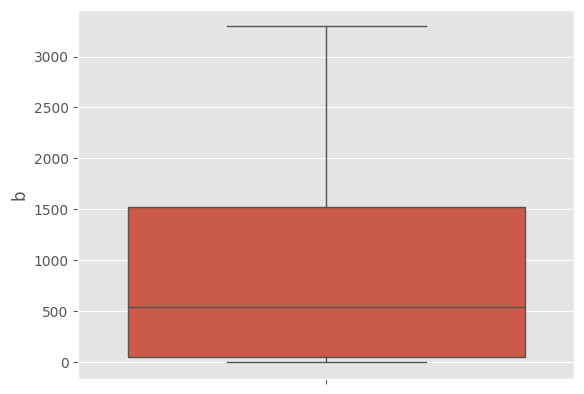

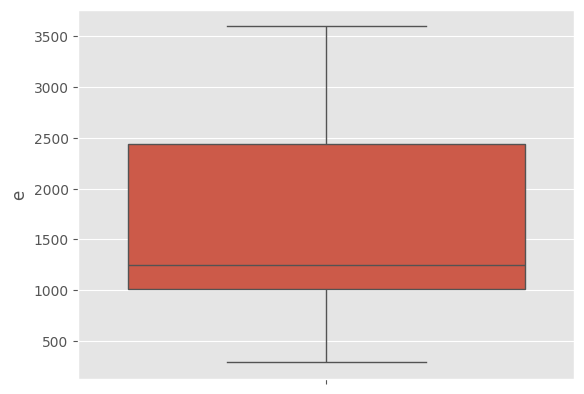

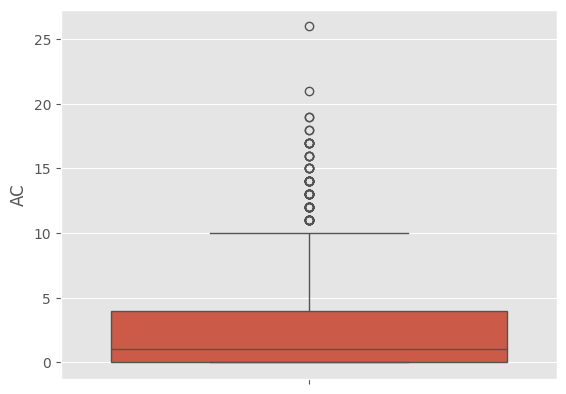

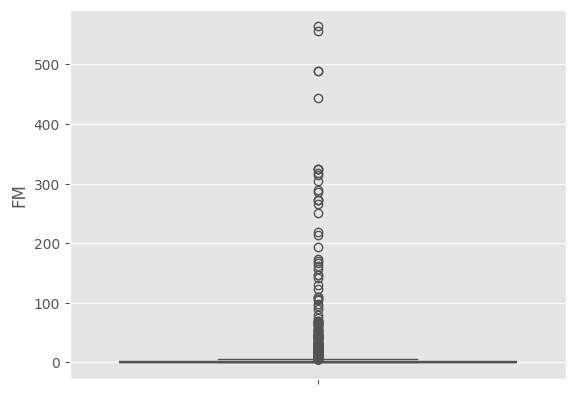

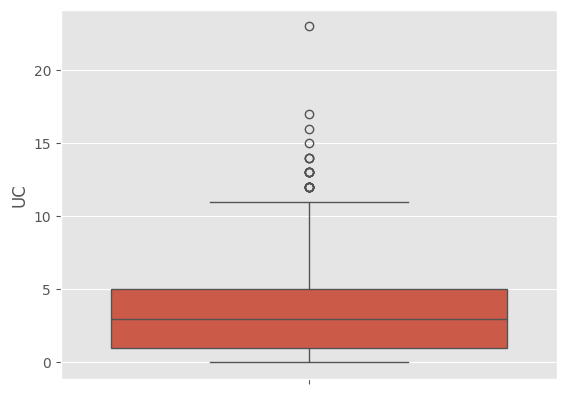

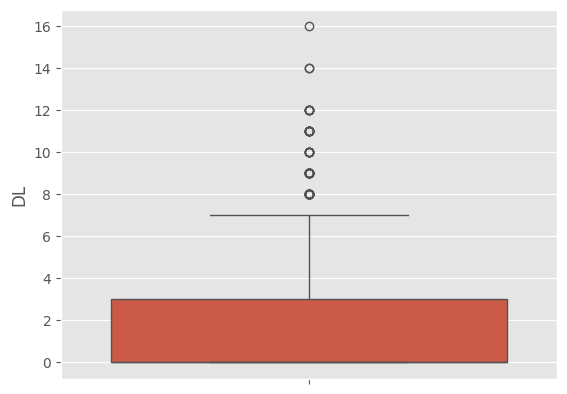

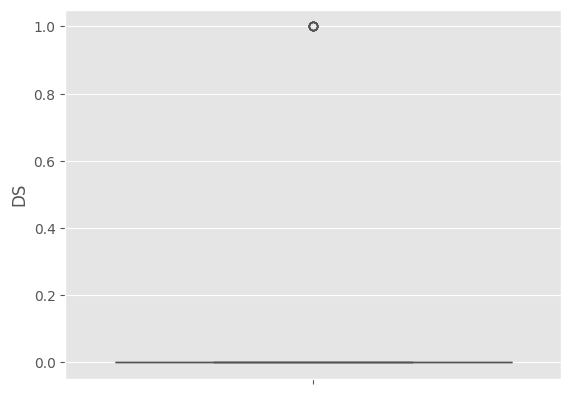

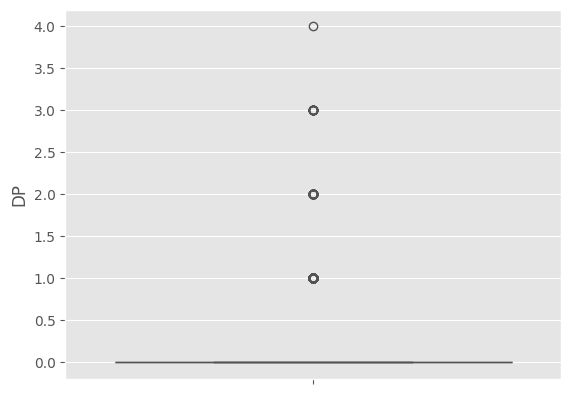

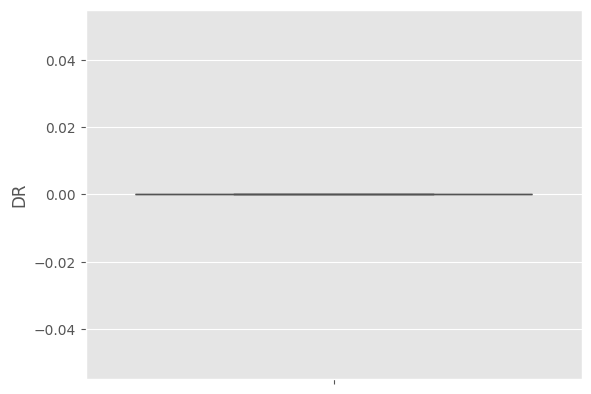

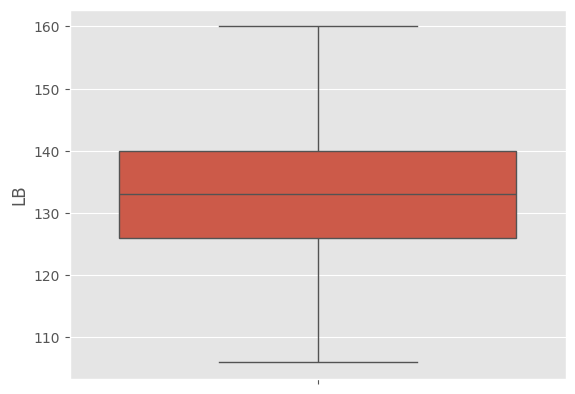

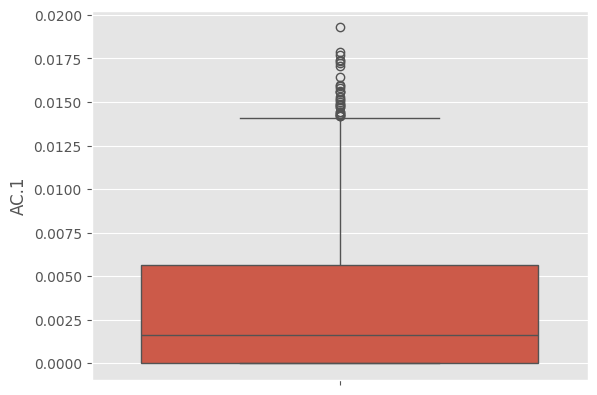

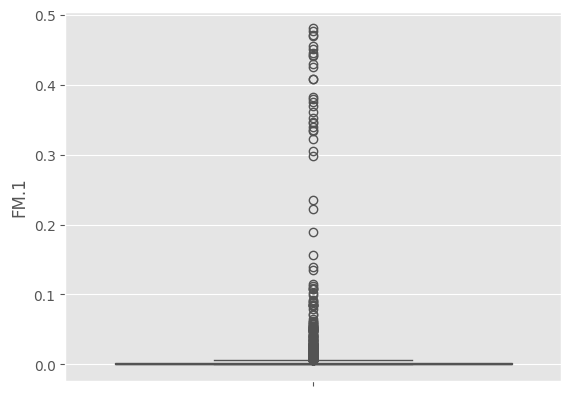

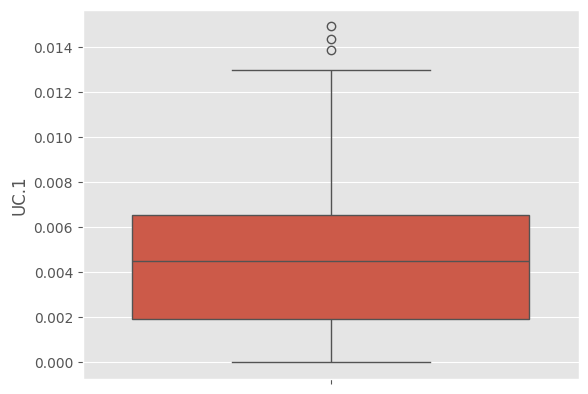

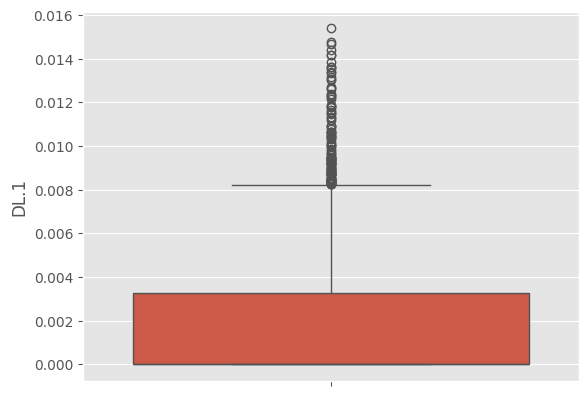

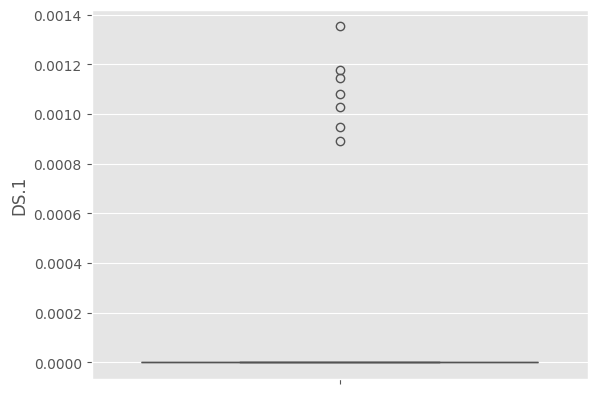

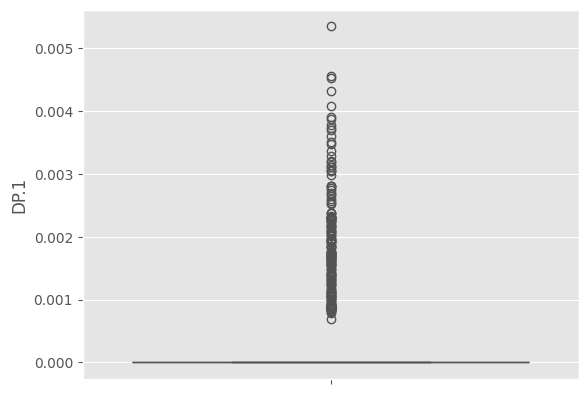

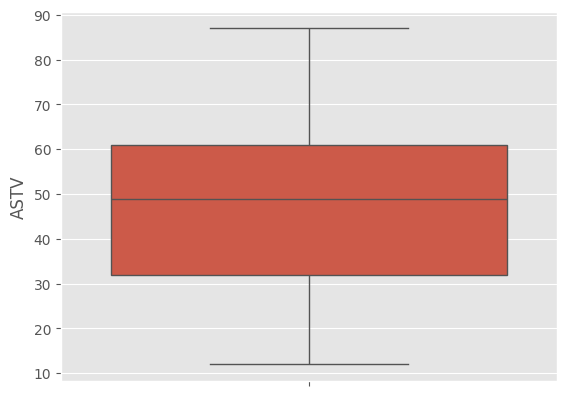

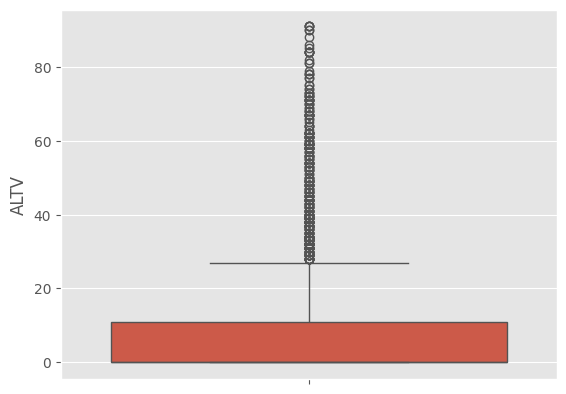

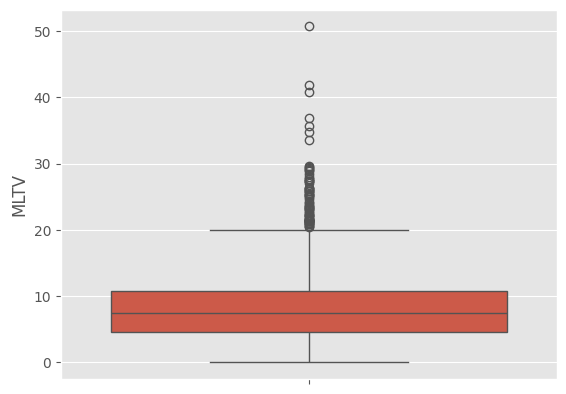

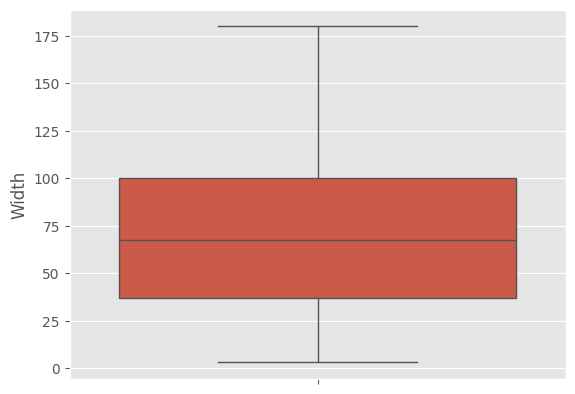

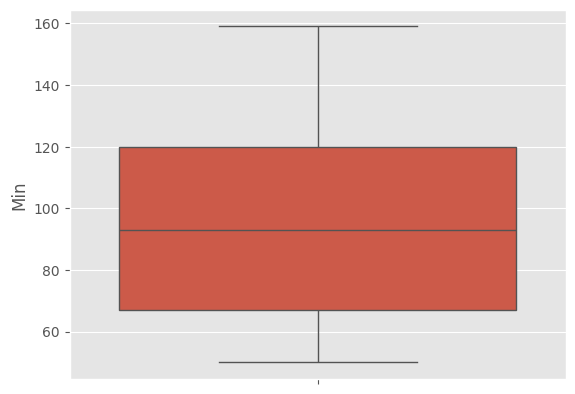

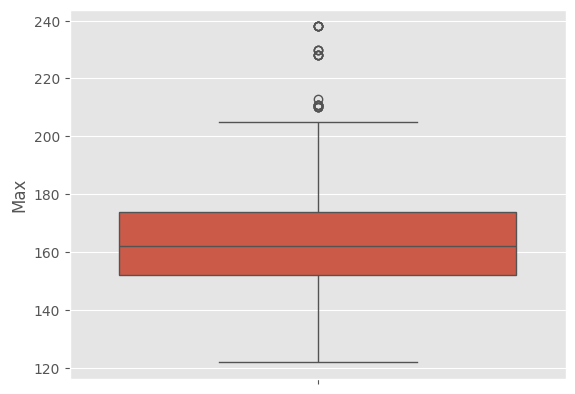

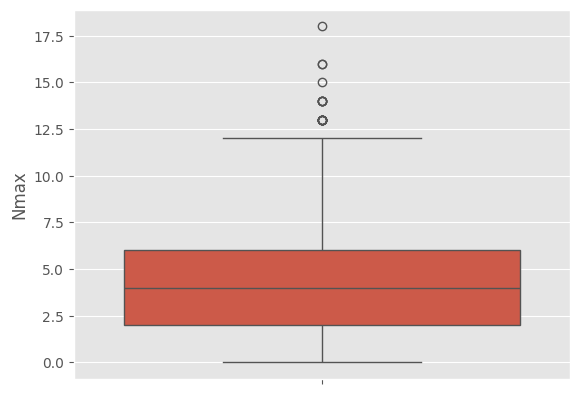

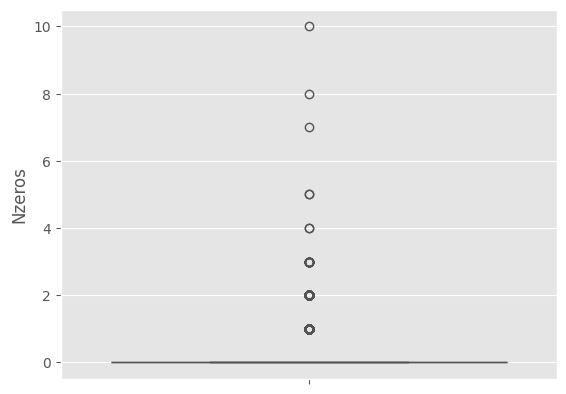

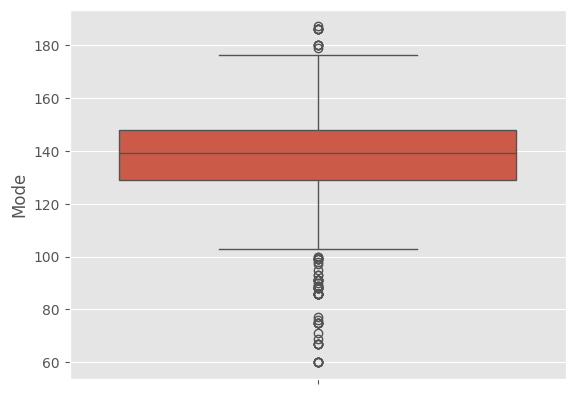

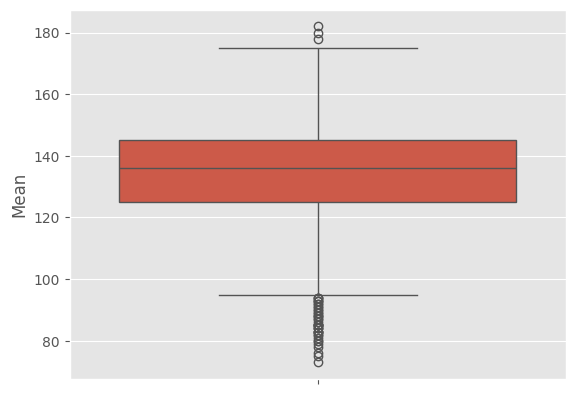

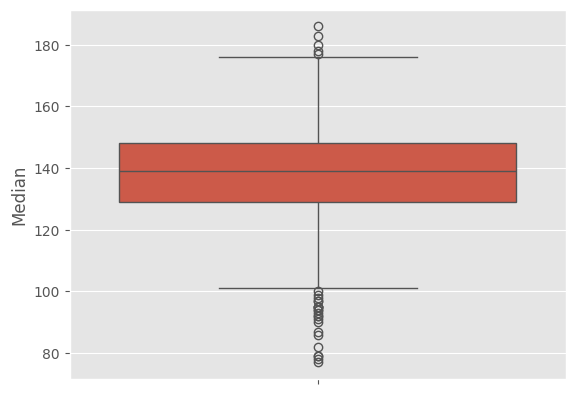

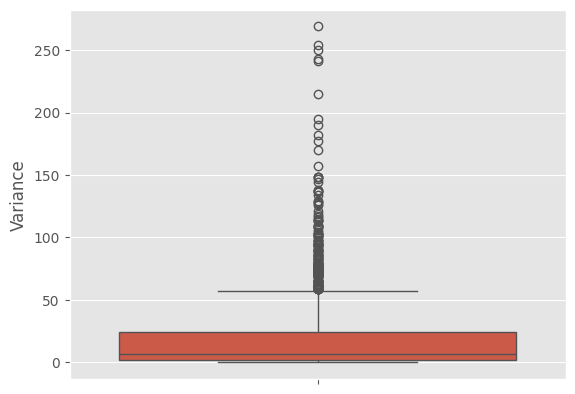

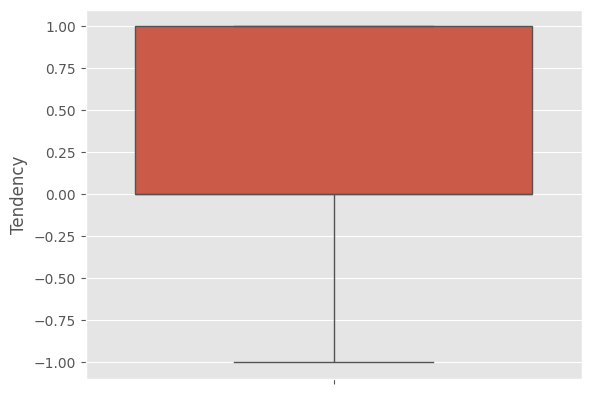

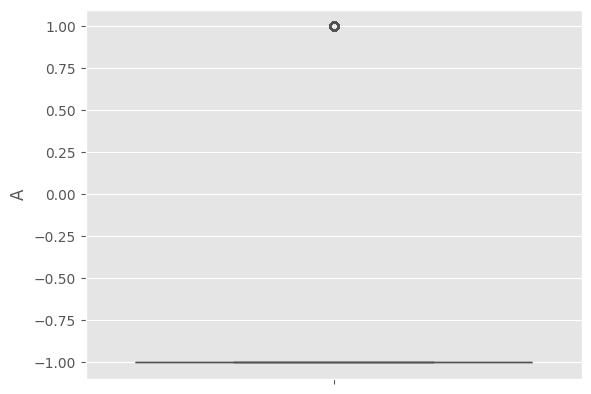

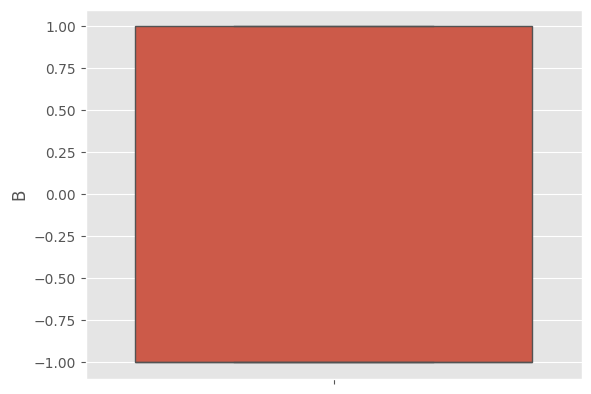

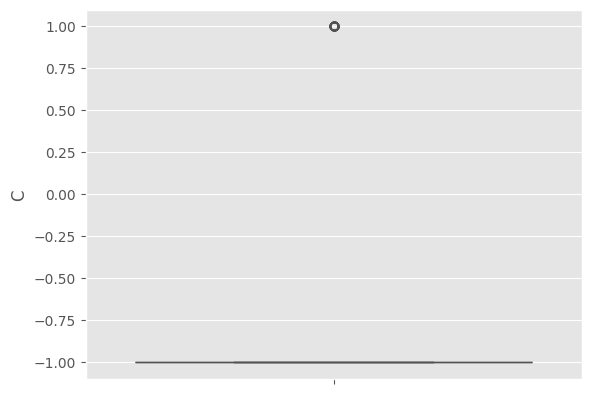

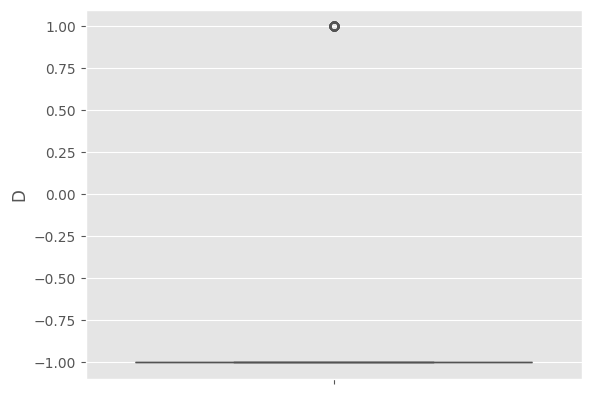

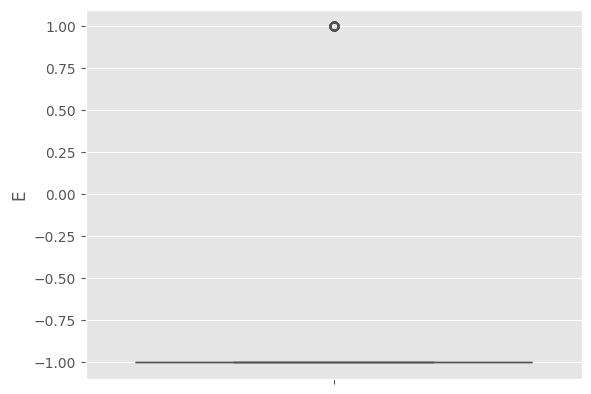

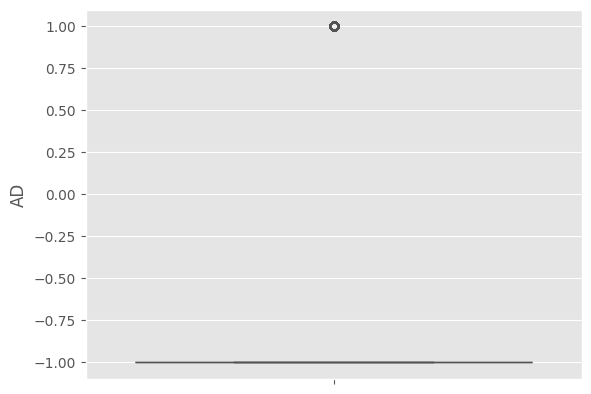

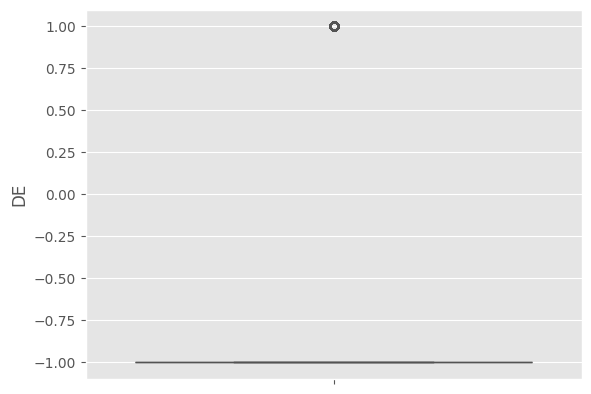

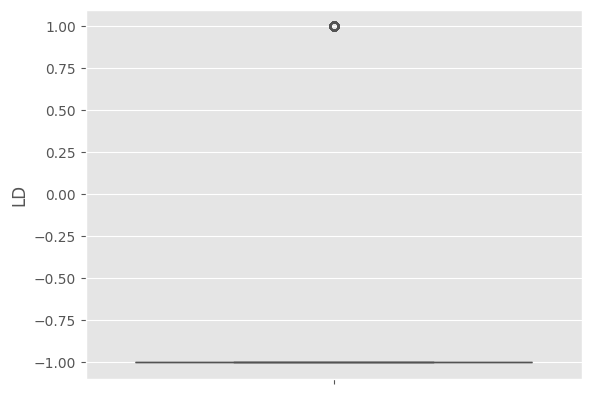

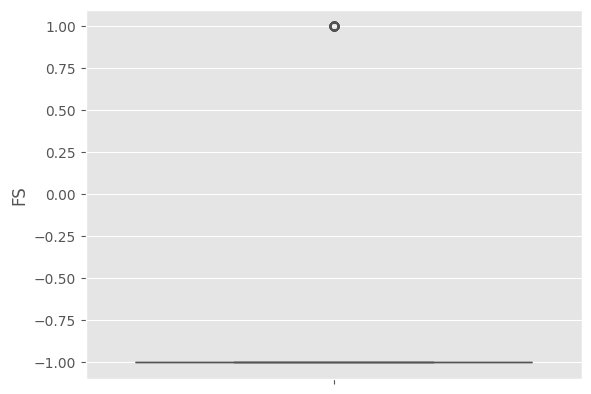

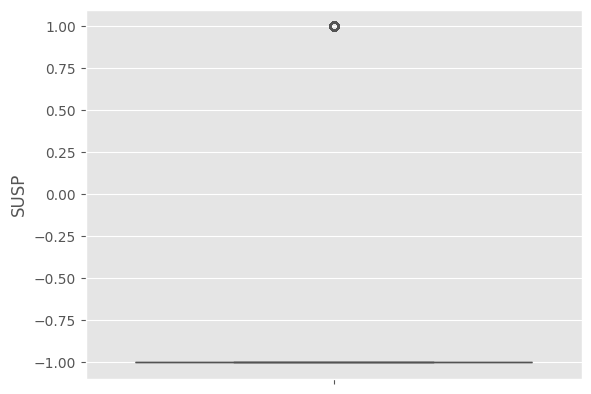

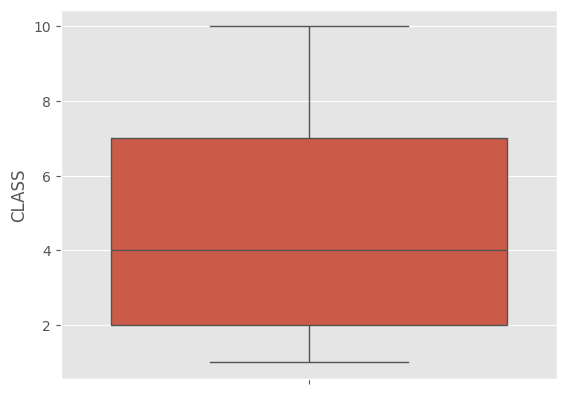

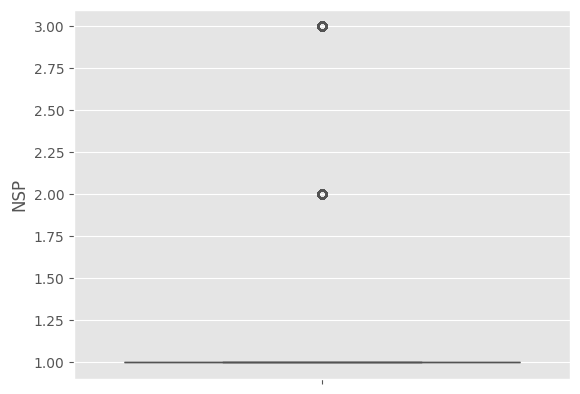

In [25]:
for col in num_cols:
  sns.boxplot(df[col])
  plt.show()

#its evident that some features might have 0 variability so we have to look for such columns and drop them

In [26]:
for col in num_cols:
  if len(df[col].unique())==1:
    print(col,df[col].unique())

DR [0.]


In [27]:
df.drop(['DR'],axis=1,inplace=True)

In [28]:
df.head(3)

,b,e,AC,FM,UC,DL,DS,DP,LB,AC.1,FM.1,UC.1,DL.1,DS.1,DP.1,ASTV,ALTV,MLTV,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,A,B,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP,MSTV
0,240.0,357.0,0.0,0.0,0.0,0.0,0.0,0.0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,43.0,2.4,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,-1.0,9.0,2.0,0.5
1,5.0,632.0,4.0,0.0,4.0,2.0,0.0,0.0,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,0.0,10.4,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,-1.0,-1.0,6.0,1.0,2.1
2,177.0,779.0,2.0,0.0,5.0,2.0,0.0,0.0,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,0.0,13.4,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,-1.0,-1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,-1.0,-1.0,6.0,1.0,2.1


give me code for iqr outlier detection and saving them to a list indexes
keep it simple

In [33]:
num_cols = num_cols.tolist()

In [34]:
num_cols.remove('DR')
num_cols

['b',
 'e',
 'AC',
 'FM',
 'UC',
 'DL',
 'DS',
 'DP',
 'LB',
 'AC.1',
 'FM.1',
 'UC.1',
 'DL.1',
 'DS.1',
 'DP.1',
 'ASTV',
 'ALTV',
 'MLTV',
 'Width',
 'Min',
 'Max',
 'Nmax',
 'Nzeros',
 'Mode',
 'Mean',
 'Median',
 'Variance',
 'Tendency',
 'A',
 'B',
 'C',
 'D',
 'E',
 'AD',
 'DE',
 'LD',
 'FS',
 'SUSP',
 'CLASS',
 'NSP']

In [36]:
df.shape

(2116, 41)

In [35]:
# List to store outlier indexes
indexes = []

# IQR Outlier Detection
for col in num_cols:

    Q1 = np.percentile(df[col],25)
    Q3 = np.percentile(df[col],75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    idx = df[(df[col] < lower_bound) | (df[col] > upper_bound)].index

    indexes.extend(idx)

    print(f"Outliers found in column {col} are {len(idx)}")

Outliers found in column b are 0
Outliers found in column e are 0
Outliers found in column AC are 83
Outliers found in column FM are 309
Outliers found in column UC are 22
Outliers found in column DL are 81
Outliers found in column DS are 7
Outliers found in column DP are 178
Outliers found in column LB are 0
Outliers found in column AC.1 are 30
Outliers found in column FM.1 are 337
Outliers found in column UC.1 are 3
Outliers found in column DL.1 are 115
Outliers found in column DS.1 are 7
Outliers found in column DP.1 are 178
Outliers found in column ASTV are 0
Outliers found in column ALTV are 306
Outliers found in column MLTV are 71
Outliers found in column Width are 0
Outliers found in column Min are 0
Outliers found in column Max are 24
Outliers found in column Nmax are 19
Outliers found in column Nzeros are 502
Outliers found in column Mode are 73
Outliers found in column Mean are 45
Outliers found in column Median are 28
Outliers found in column Variance are 184
Outliers found 

In [40]:
len(set(indexes))

1774

# we can see that we have 1774 outliers and if we drop these we will be left with 300 data points that will not be good for model building hence we will not drop the outliers but we will cap them

In [41]:
# Capping using IQR and np.percentile
for col in num_cols:

    Q1 = np.percentile(df[col], 25)
    Q3 = np.percentile(df[col], 75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Capping
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])


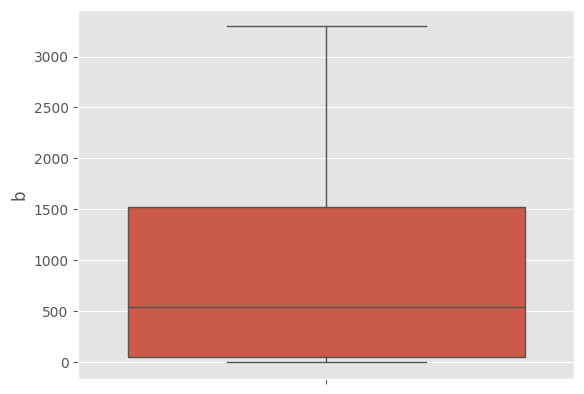

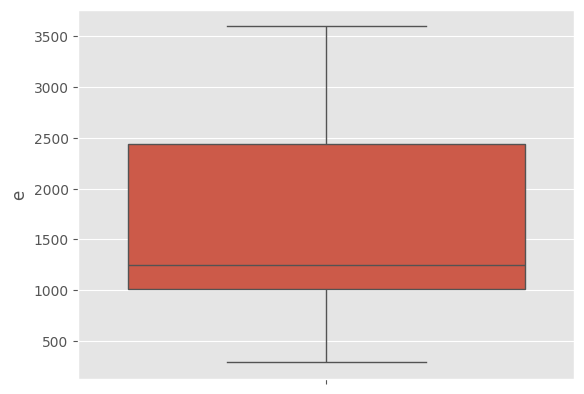

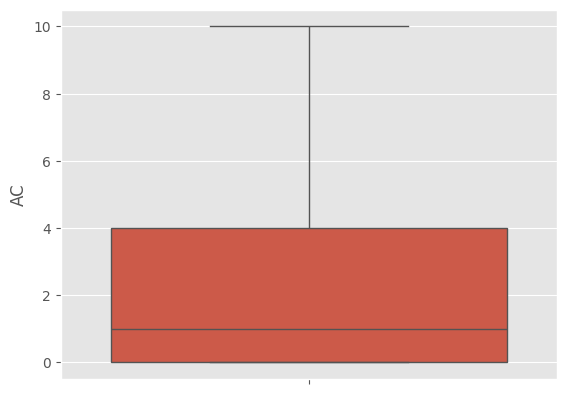

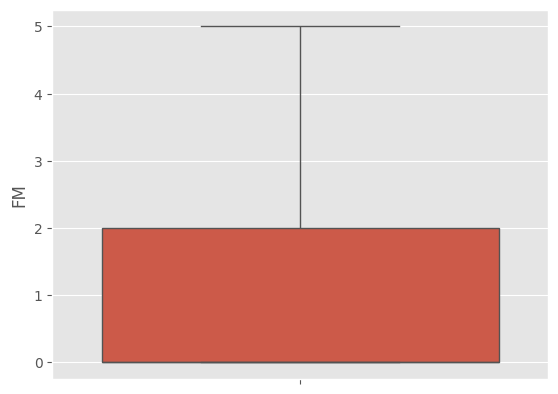

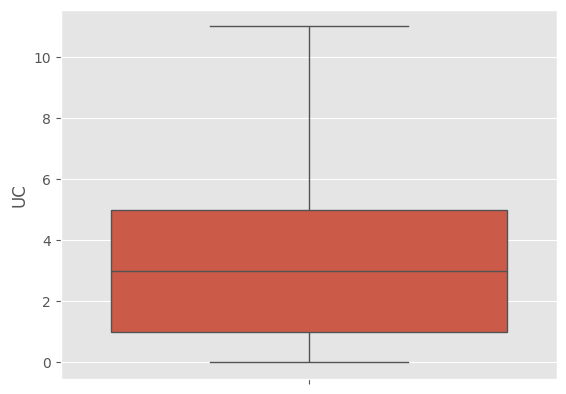

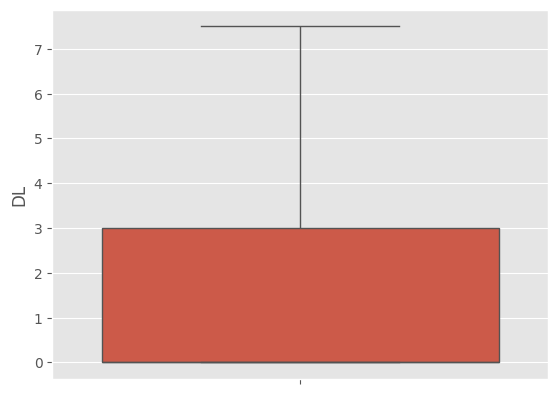

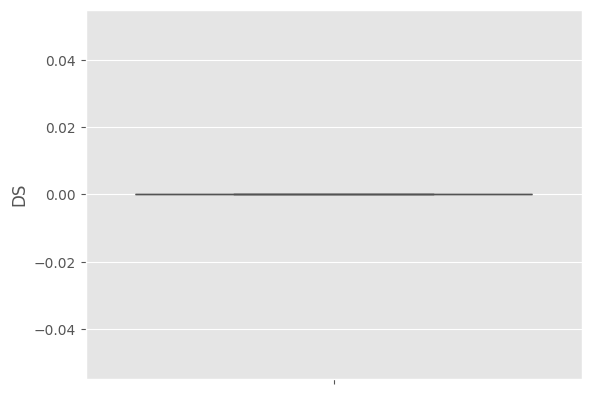

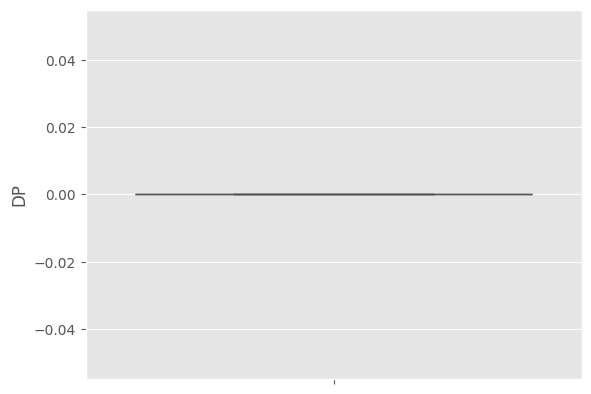

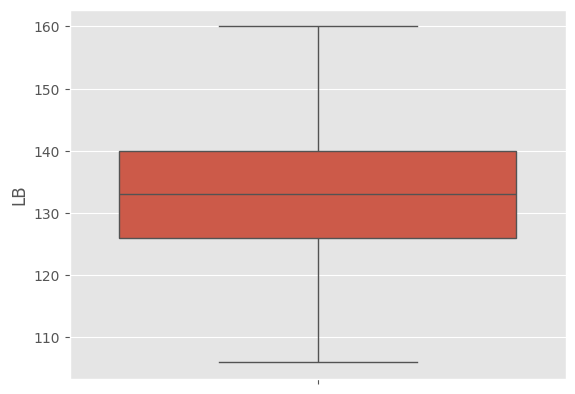

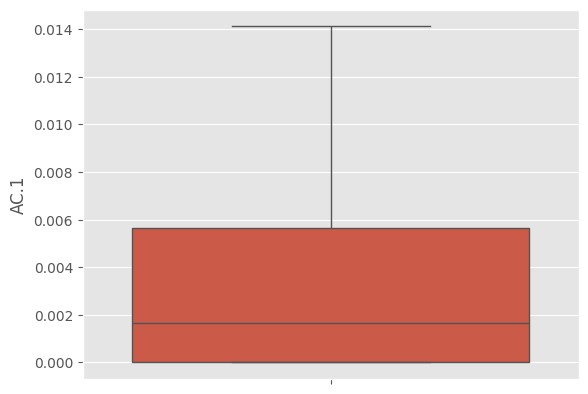

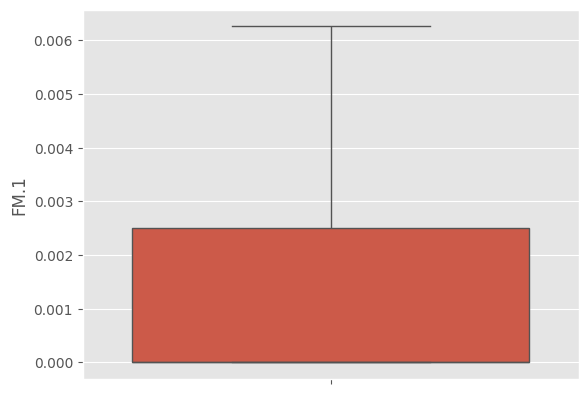

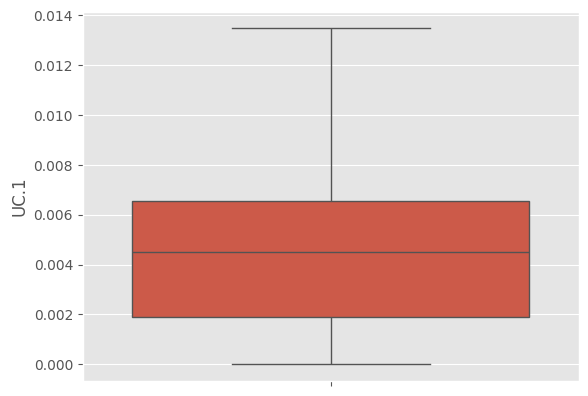

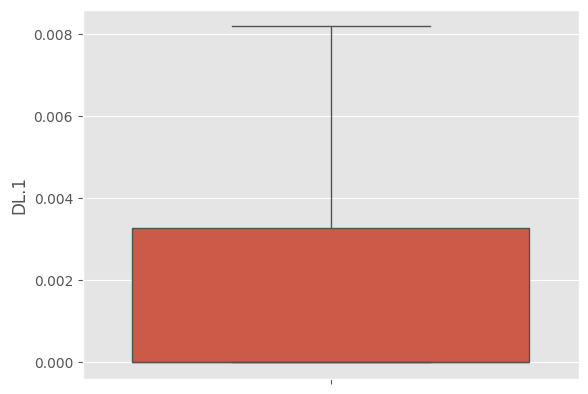

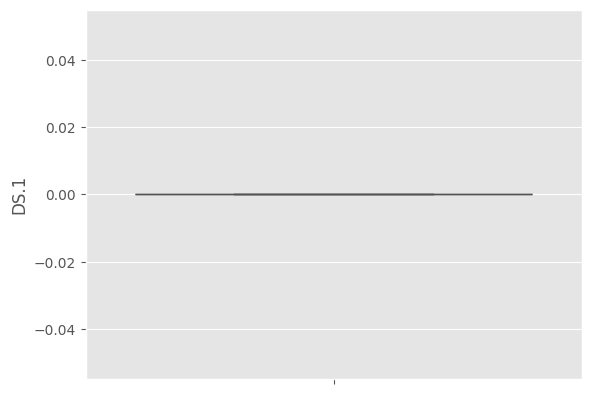

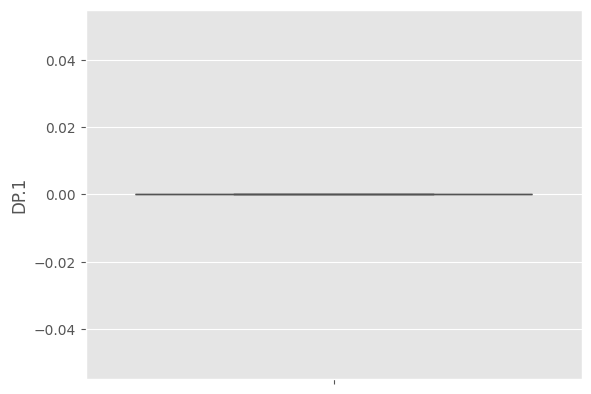

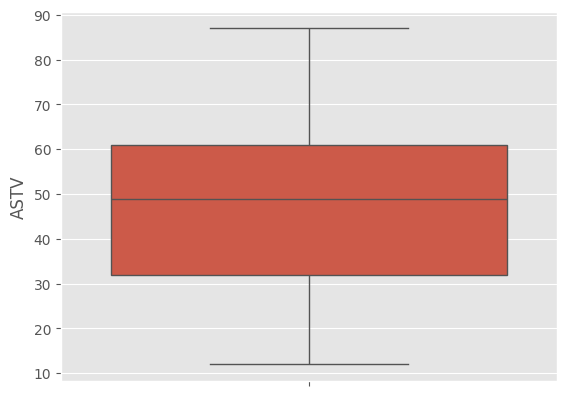

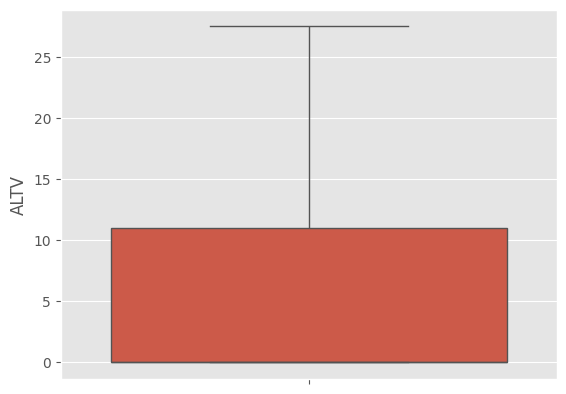

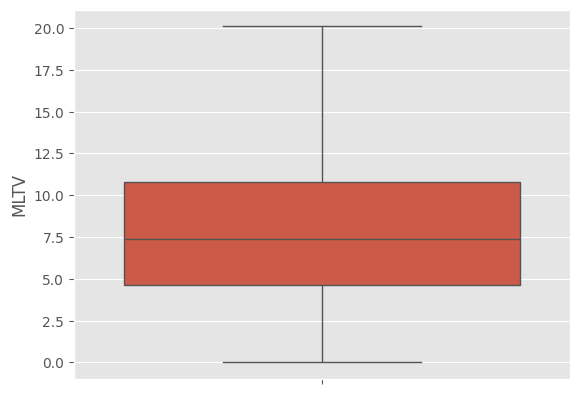

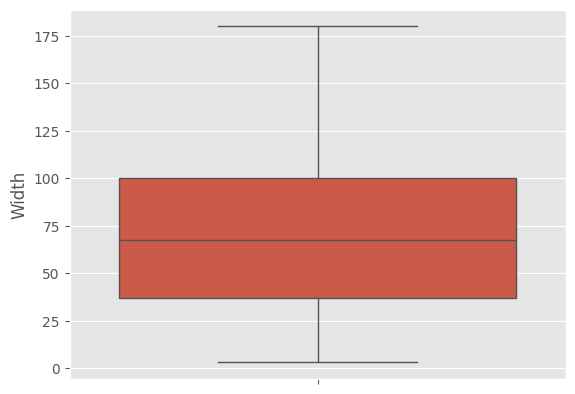

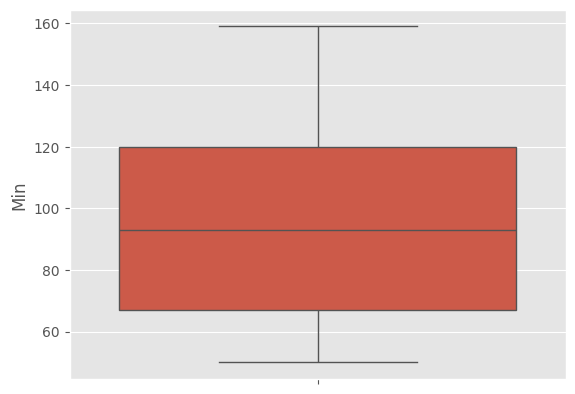

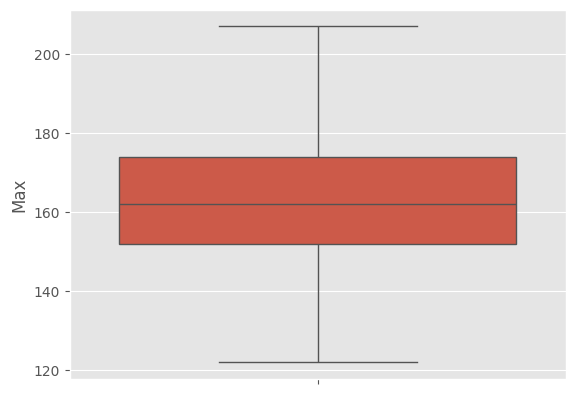

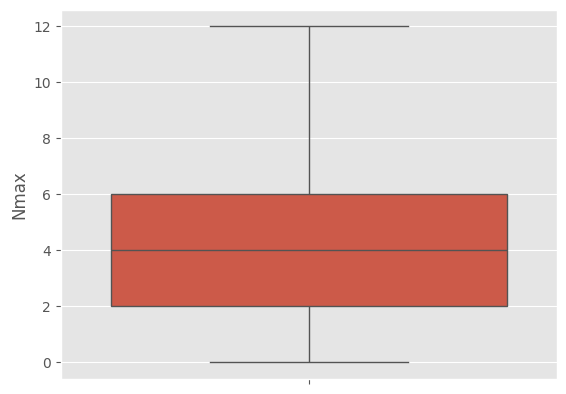

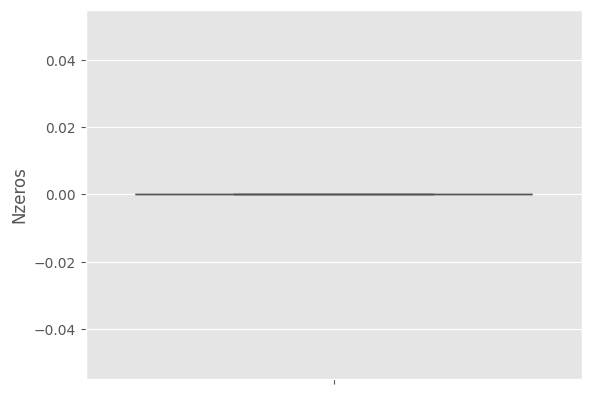

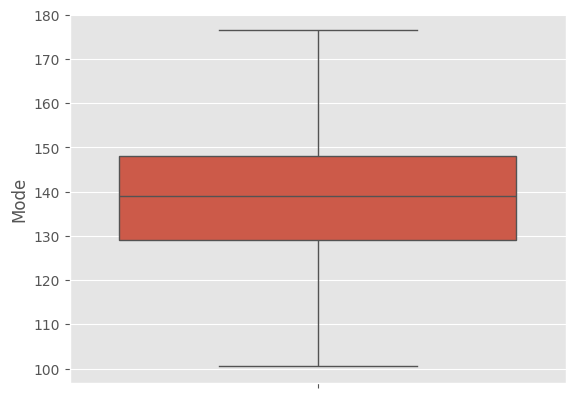

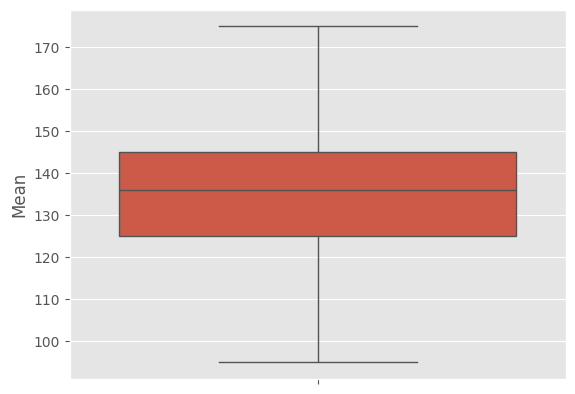

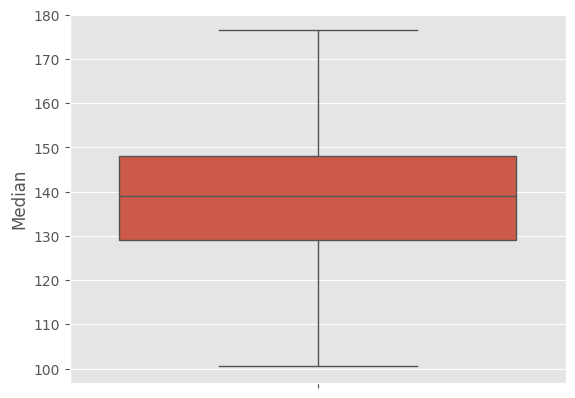

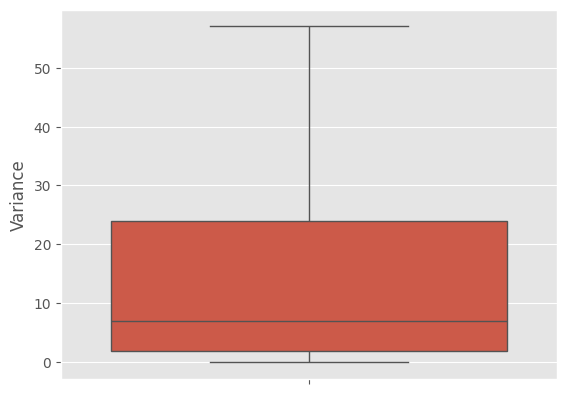

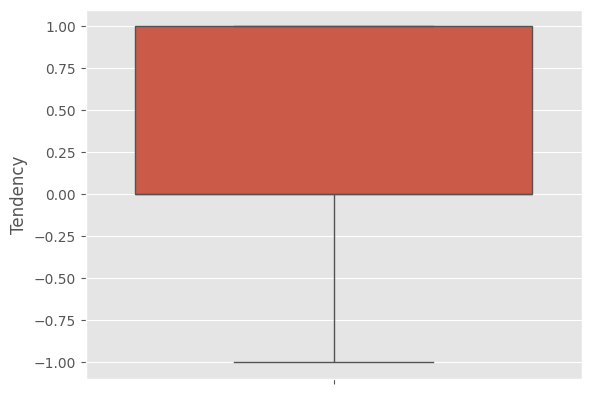

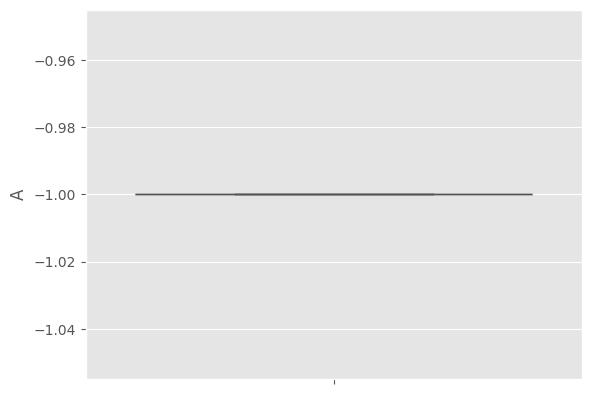

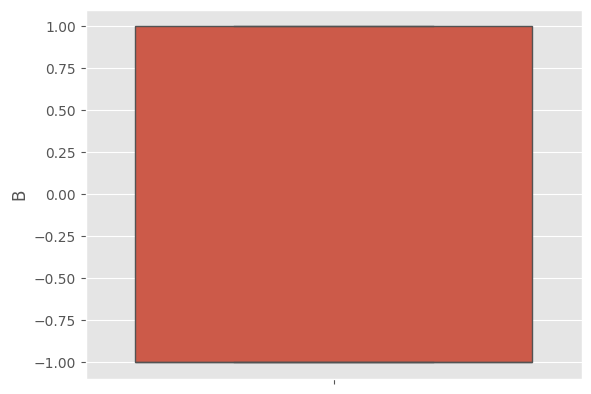

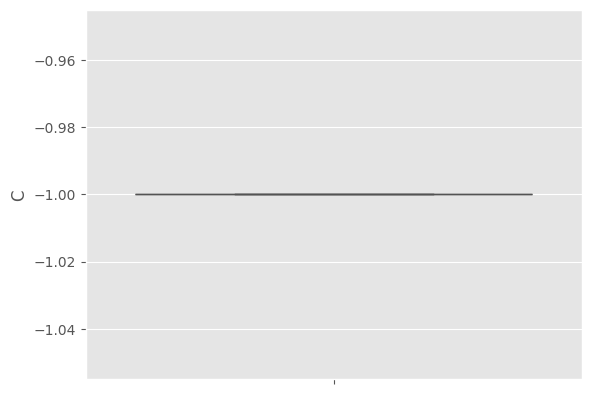

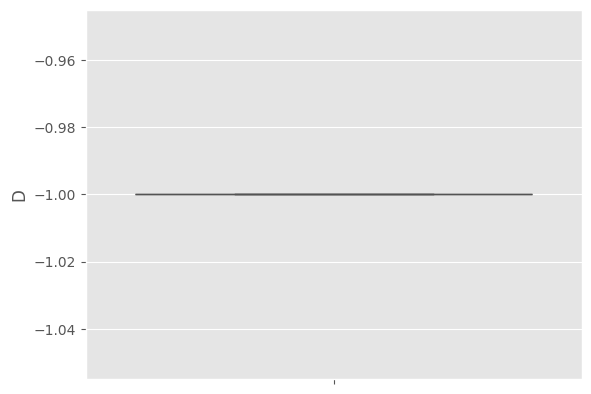

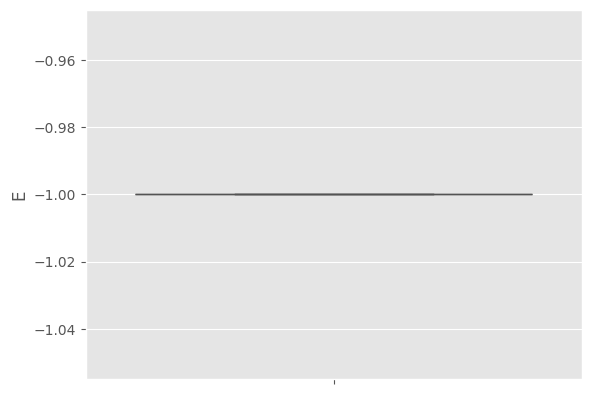

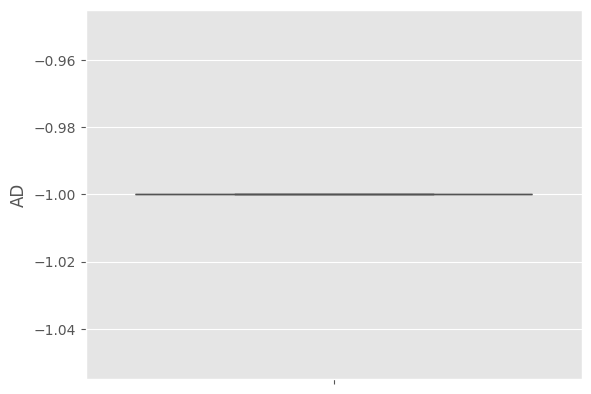

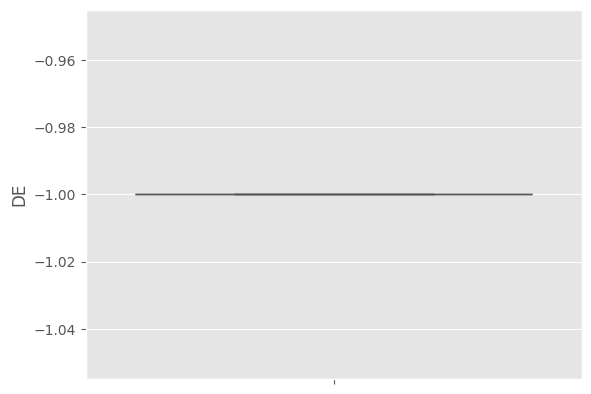

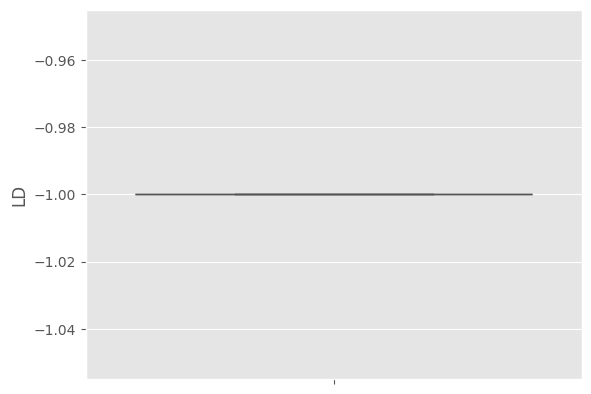

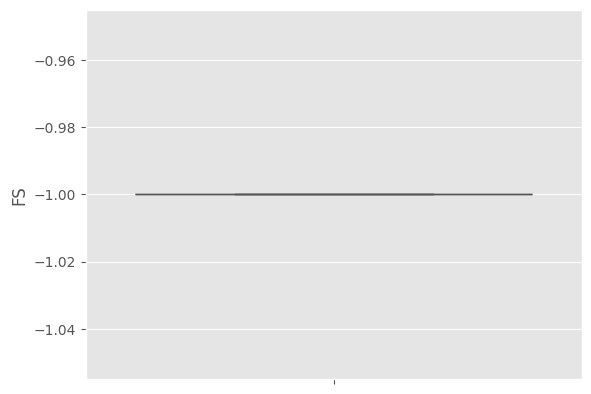

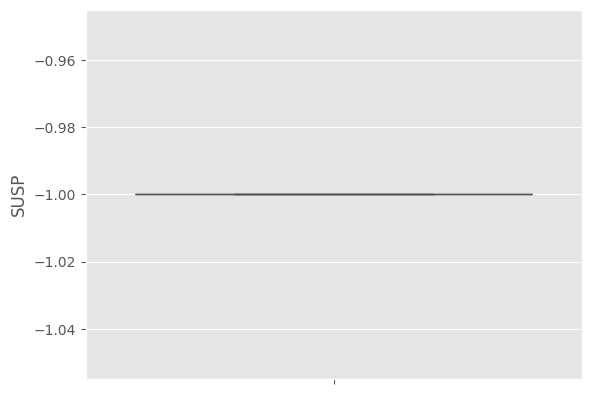

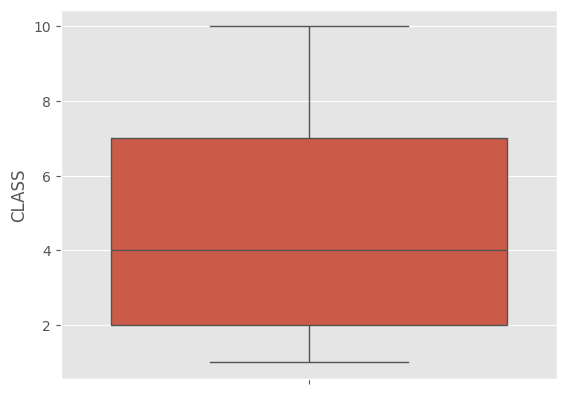

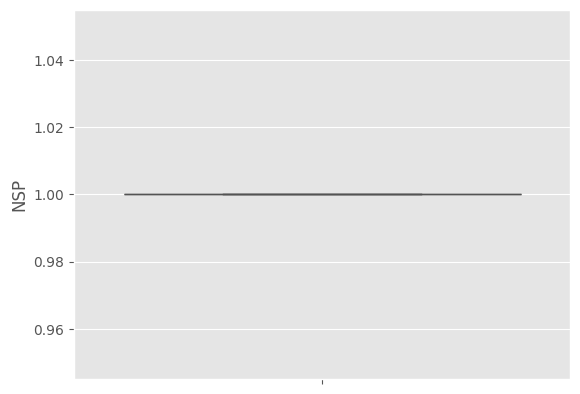

In [42]:
for col in num_cols:
  sns.boxplot(df[col])
  plt.show()

In [43]:
df[num_cols].var()

,0
b,801053.884897
e,868170.476525
AC,9.784250
FM,3.592309
UC,7.567652
DL,5.113352
DS,0.000000
DP,0.000000
LB,96.773679
AC.1,0.000014


In [45]:
zero_var_cols = []
for col in num_cols:
  if df[col].var()==0:
    print(col)
    zero_var_cols.append(col)

DS
DP
DS.1
DP.1
Nzeros
A
C
D
E
AD
DE
LD
FS
SUSP
NSP


In [46]:
df.drop(zero_var_cols,axis=1,inplace=True)

In [47]:
df.columns

Index(['b', 'e', 'AC', 'FM', 'UC', 'DL', 'LB', 'AC.1', 'FM.1', 'UC.1', 'DL.1',
       'ASTV', 'ALTV', 'MLTV', 'Width', 'Min', 'Max', 'Nmax', 'Mode', 'Mean',
       'Median', 'Variance', 'Tendency', 'B', 'CLASS', 'MSTV'],
      dtype='object')

Index(['b', 'e', 'AC', 'FM', 'UC', 'DL', 'LB', 'AC.1', 'FM.1', 'UC.1', 'DL.1',
       'ASTV', 'ALTV', 'MLTV', 'Width', 'Min', 'Max', 'Nmax', 'Mode', 'Mean',
       'Median', 'Variance', 'Tendency', 'B', 'CLASS', 'MSTV'],

okay so i used capping and some columns became exactly like 0 variance and i am left with these columns
now i need you to give me the code for EDA
Univariate Analysis
Tasks
Histograms
Density plots
Boxplots
Distribution analysis

Bivariate Analysis
Tasks
Scatterplots
Correlation heatmaps
Pairwise feature analysis

Multivariate Analysis
Tasks
Sensor interaction analysis
Feature relationship exploration
Physiological trend visualization

Target Variable Analysis
Tasks
MSTV distribution analysis
Variability pattern exploration

Expected Insights
Examples:
Relationship between accelerations and MSTV
Influence of uterine contractions on variability
Correlation between abnormal variability indicators and MSTV

keep the code simple and minimal

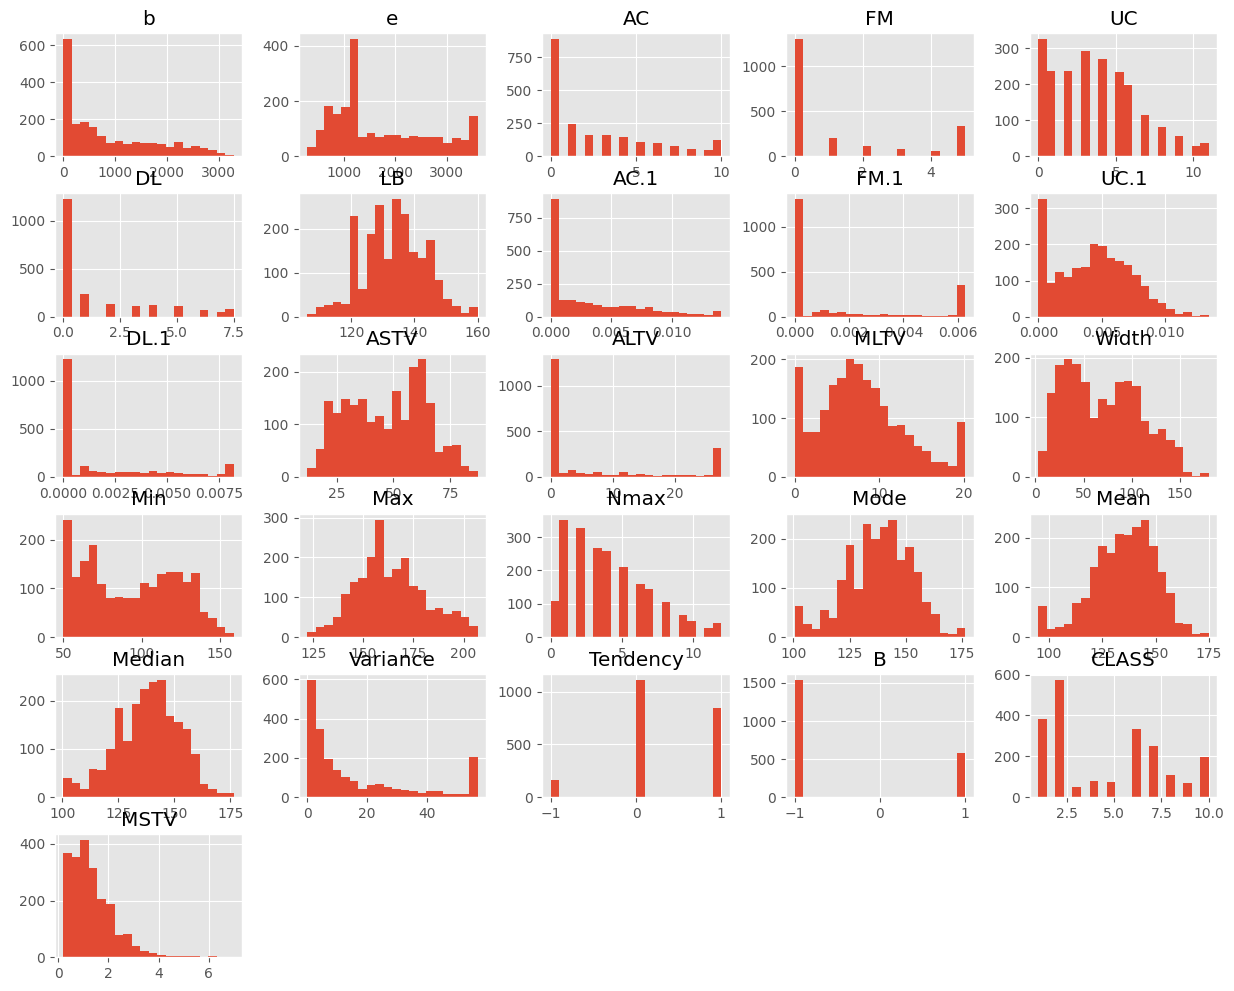

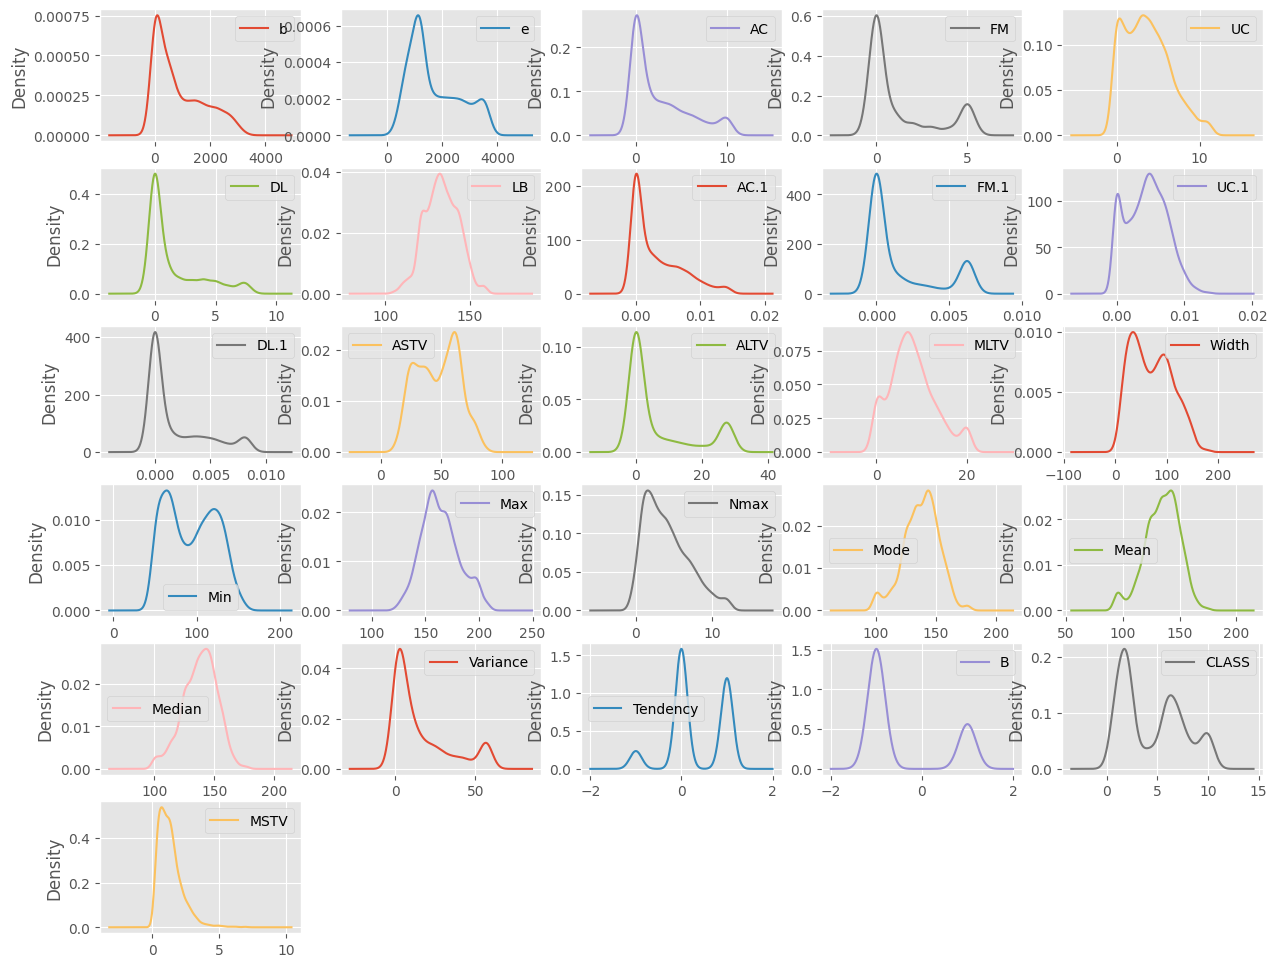

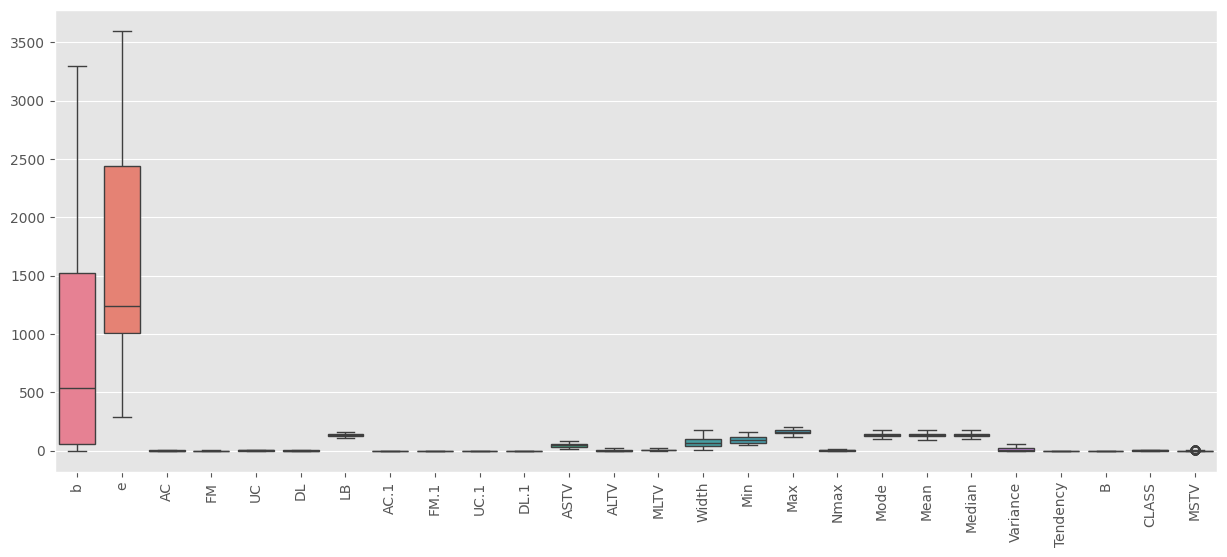

In [48]:
# -----------------------------
# UNIVARIATE ANALYSIS
# -----------------------------

# Histograms
df.hist(figsize=(15, 12), bins=20)
plt.show()

# Density Plots
df.plot(kind='density', subplots=True, layout=(6,5), figsize=(15,12), sharex=False)
plt.show()

# Boxplots
plt.figure(figsize=(15,6))
sns.boxplot(data=df)
plt.xticks(rotation=90)
plt.show()

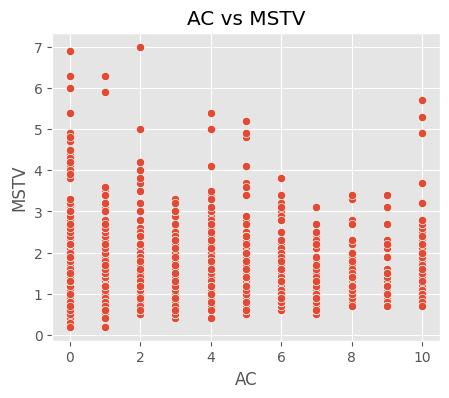

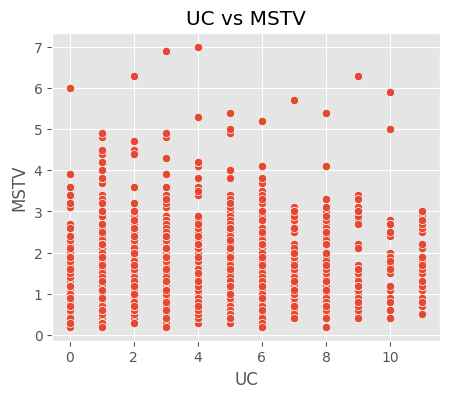

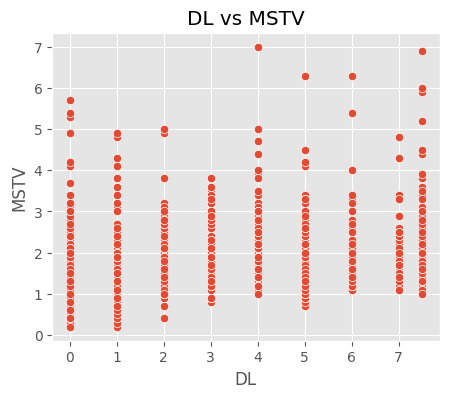

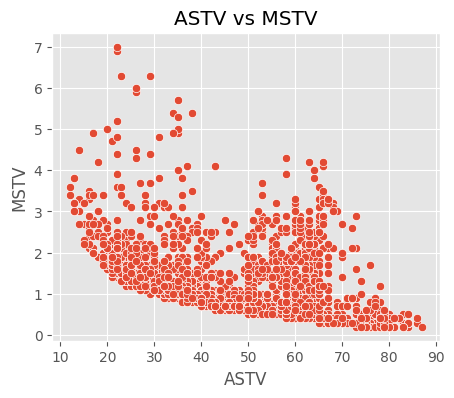

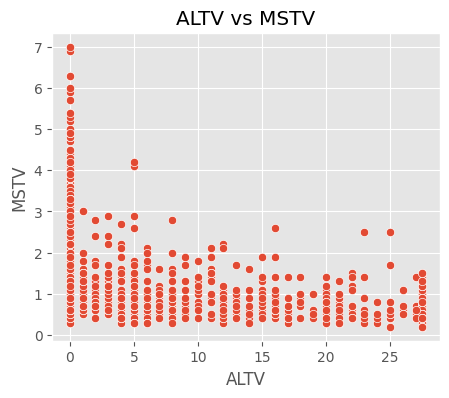

In [49]:
# -----------------------------
# BIVARIATE ANALYSIS
# -----------------------------

# Scatterplots with target
features = ['AC', 'UC', 'DL', 'ASTV', 'ALTV']

for col in features:
    plt.figure(figsize=(5,4))
    sns.scatterplot(x=df[col], y=df['MSTV'])
    plt.title(f"{col} vs MSTV")
    plt.show()




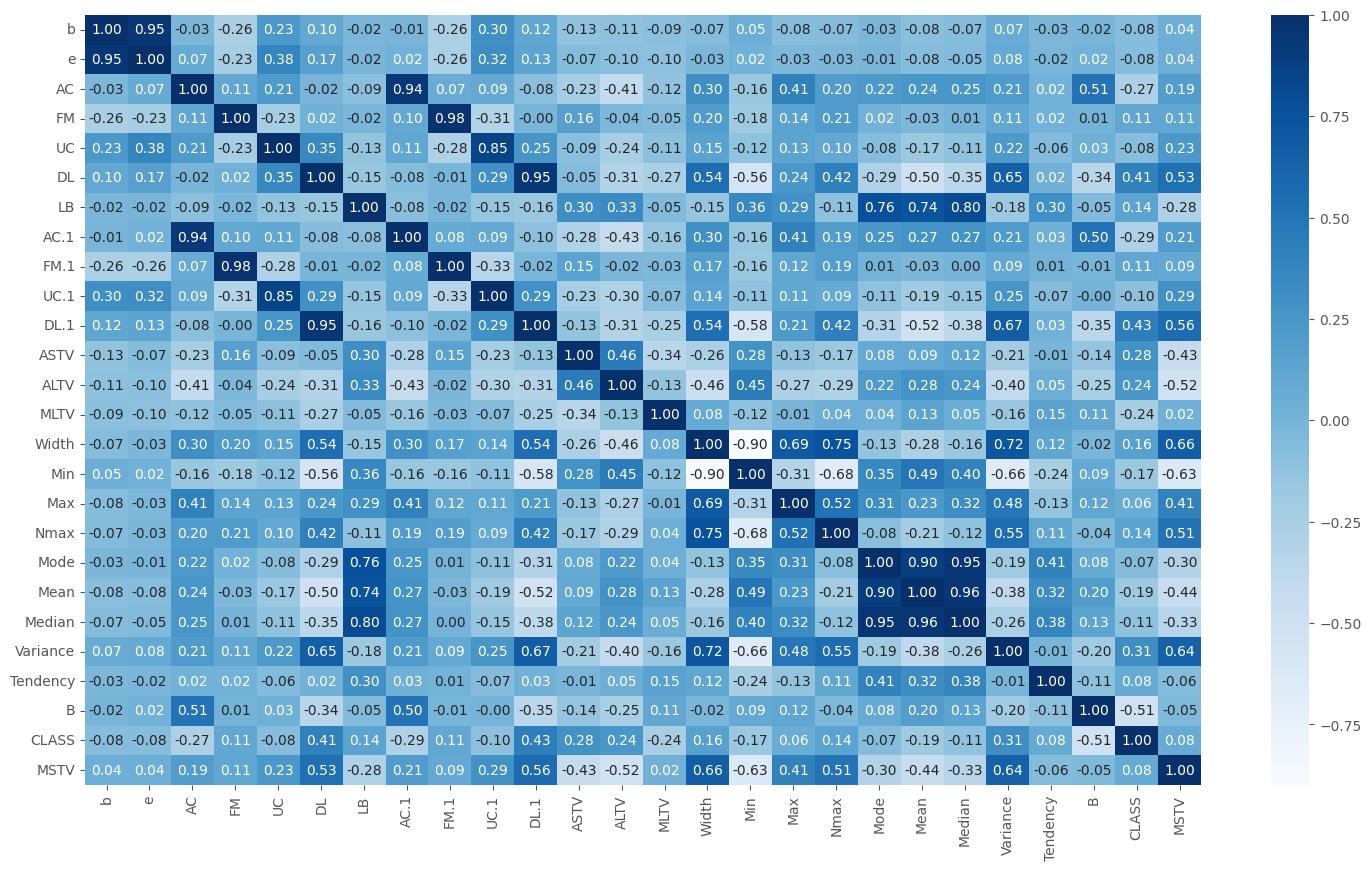

In [53]:
# Correlation Heatmap
plt.figure(figsize=(18,10))
sns.heatmap(df.corr(), cmap='Blues',annot=True,fmt='.2f')
plt.show()

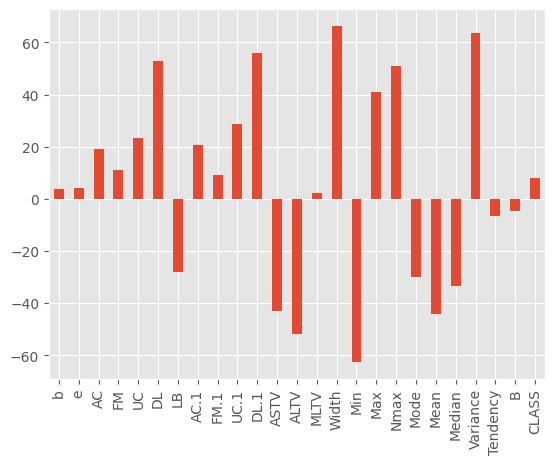

In [57]:
(df.corr()['MSTV'].drop(['MSTV'])*100).plot.bar()
plt.show()

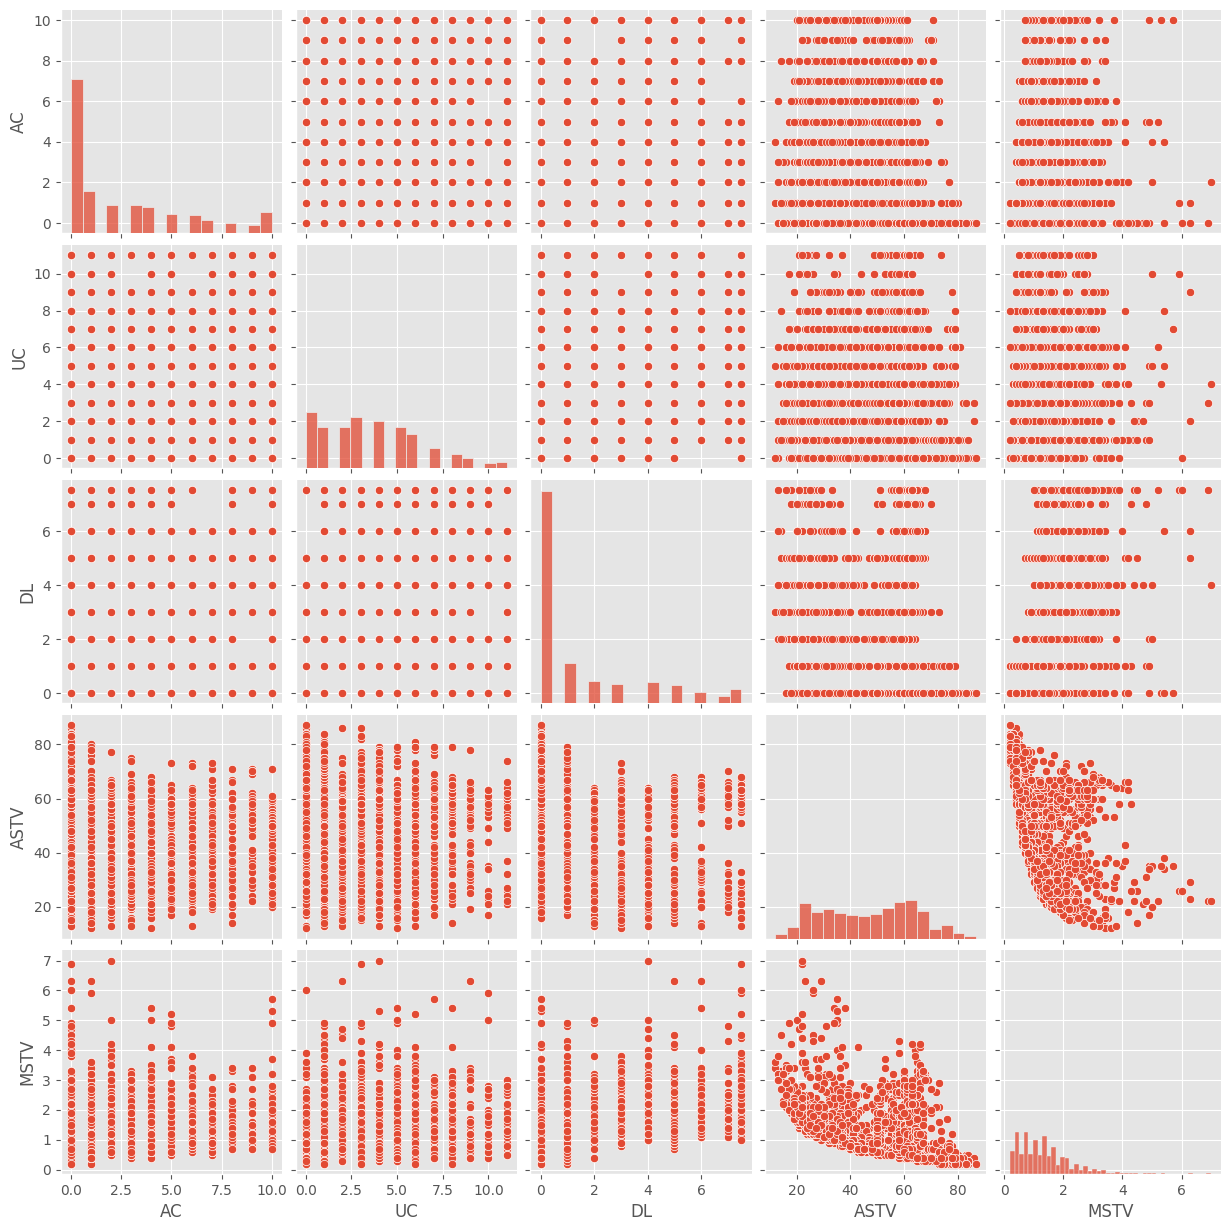

In [58]:
# Pairwise Feature Analysis
sns.pairplot(df[['AC', 'UC', 'DL', 'ASTV', 'MSTV']])
plt.show()

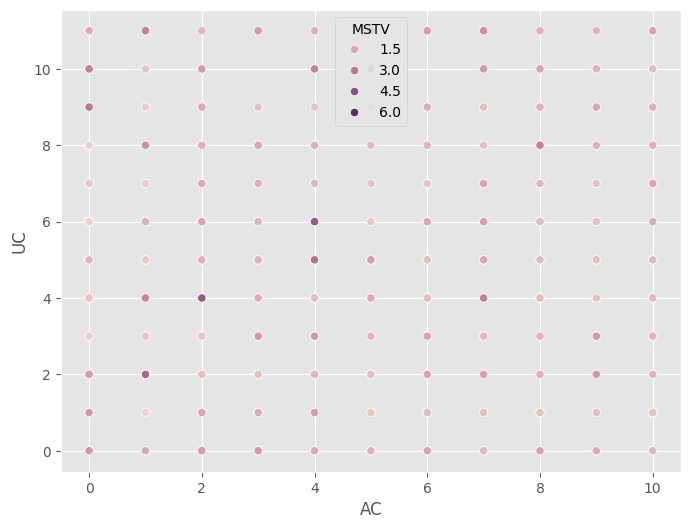

In [59]:
# -----------------------------
# MULTIVARIATE ANALYSIS
# -----------------------------

# Sensor Interaction Analysis
plt.figure(figsize=(8,6))
sns.scatterplot(x=df['AC'], y=df['UC'], hue=df['MSTV'])
plt.show()


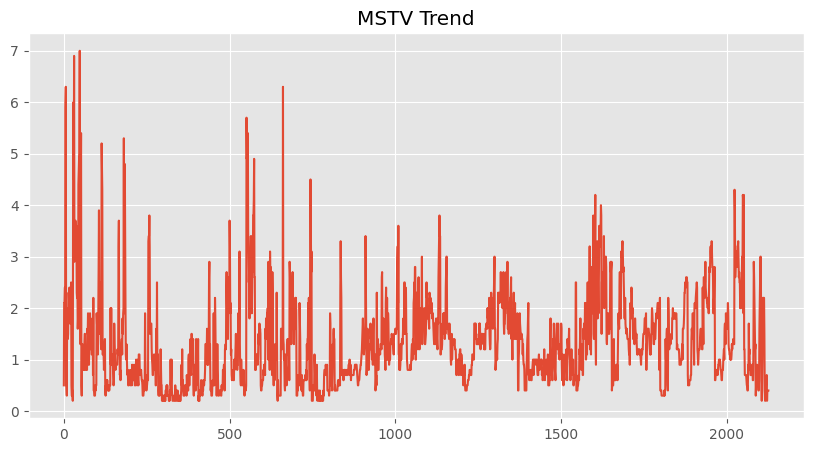

In [60]:
# Physiological Trend Visualization
plt.figure(figsize=(10,5))
plt.plot(df['MSTV'])
plt.title("MSTV Trend")
plt.show()

In [61]:
from scipy.stats import pearsonr, spearmanr, f_oneway, shapiro


target = 'MSTV'

# -----------------------------
# PEARSON CORRELATION
# -----------------------------

print("PEARSON CORRELATION\n")

for col in df.select_dtypes(include=['int64', 'float64']).columns:

    if col != target:
        corr, p_value = pearsonr(df[col], df[target])

        print(f"{col} -> Correlation: {round(corr,3)} | P-value: {p_value}")

        if p_value < 0.05:
            print("Significant\n")
        else:
            print("Not Significant\n")


# -----------------------------
# SPEARMAN CORRELATION
# -----------------------------

print("\nSPEARMAN CORRELATION\n")

for col in df.select_dtypes(include=['int64', 'float64']).columns:

    if col != target:
        corr, p_value = spearmanr(df[col], df[target])

        print(f"{col} -> Correlation: {round(corr,3)} | P-value: {p_value}")

        if p_value < 0.05:
            print("Significant\n")
        else:
            print("Not Significant\n")


# -----------------------------
# ANOVA
# -----------------------------

print("\nANOVA TEST\n")

groups = []

for value in df['CLASS'].unique():
    groups.append(df[df['CLASS'] == value][target])

f_stat, p_value = f_oneway(*groups)

print(f"F-Statistic: {f_stat}")
print(f"P-value: {p_value}")

if p_value < 0.05:
    print("Significant Difference Between Groups")
else:
    print("No Significant Difference Between Groups")


# -----------------------------
# SHAPIRO-WILK NORMALITY TEST
# -----------------------------

print("\nSHAPIRO-WILK TEST\n")

for col in df.select_dtypes(include=['int64', 'float64']).columns:

    stat, p_value = shapiro(df[col])

    print(f"{col} -> P-value: {p_value}")

    if p_value < 0.05:
        print("Not Normally Distributed\n")
    else:
        print("Normally Distributed\n")



PEARSON CORRELATION

b -> Correlation: 0.039 | P-value: 0.07149651291683293
Not Significant

e -> Correlation: 0.043 | P-value: 0.046019403042649606
Significant

AC -> Correlation: 0.193 | P-value: 3.0165893005242565e-19
Significant

FM -> Correlation: 0.113 | P-value: 1.9785997459499108e-07
Significant

UC -> Correlation: 0.234 | P-value: 8.345893468118991e-28
Significant

DL -> Correlation: 0.528 | P-value: 3.4742088371907415e-152
Significant

LB -> Correlation: -0.279 | P-value: 3.4411662536888854e-39
Significant

AC.1 -> Correlation: 0.206 | P-value: 1.288085178079482e-21
Significant

FM.1 -> Correlation: 0.091 | P-value: 2.5922640096400245e-05
Significant

UC.1 -> Correlation: 0.286 | P-value: 3.021010504177201e-41
Significant

DL.1 -> Correlation: 0.56 | P-value: 5.409186364803821e-175
Significant

ASTV -> Correlation: -0.43 | P-value: 9.000800069821992e-96
Significant

ALTV -> Correlation: -0.518 | P-value: 2.4980025320512653e-145
Significant

MLTV -> Correlation: 0.024 | P-valu

| Test                                  | Purpose                                                | Key Findings                                                                                                     | Significance                                                                   |
| ------------------------------------- | ------------------------------------------------------ | ---------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------ |
| **Pearson Correlation**               | Measures linear relationship between features and MSTV | Strong positive correlations observed with `Width (0.663)`, `Variance (0.635)`, `DL.1 (0.560)`, and `DL (0.528)` | Most variables showed statistically significant linear relationships with MSTV |
| **Pearson Negative Correlations**     | Identify inverse relationships                         | Strong negative relationships found with `Min (-0.626)`, `ALTV (-0.518)`, and `ASTV (-0.430)`                    | Significant inverse relationships with fetal variability                       |
| **Non-Significant Pearson Features**  | Detect weak/nonlinear relationships                    | `b`, `MLTV` showed weak and non-significant relationships with MSTV                                              | No significant linear association                                              |
| **Spearman Correlation**              | Measures monotonic nonlinear relationships             | Strong nonlinear positive relationships found with `Variance (0.778)`, `Width (0.717)`, `DL.1 (0.619)`           | Significant nonlinear associations detected                                    |
| **Spearman Negative Correlations**    | Detect inverse monotonic trends                        | Strong negative relationships found with `Min (-0.700)` and `ALTV (-0.682)`                                      | Significant monotonic inverse trends                                           |
| **Non-Significant Spearman Features** | Identify weak monotonic relationships                  | `MLTV`, `Tendency`, and `B` were not significant                                                                 | No monotonic relationship observed                                             |
| **ANOVA Test**                        | Compare MSTV variance across physiological groups      | F-Statistic = `165.64`, P-value = `2.53e-237`                                                                    | Significant differences exist among fetal monitoring groups                    |
| **Shapiro-Wilk Normality Test**       | Check normality assumption of features                 | All variables including MSTV had P-value < 0.05                                                                  | Data is not normally distributed                                               |
| **Variance Analysis**                 | Analyze variability across measurements                | Features like `Variance`, `Width`, and `DL.1` showed high variability                                            | Indicates strong physiological fluctuation patterns                            |


#Key Insights

- Accelerations (AC, AC.1) showed positive relationships with MSTV, indicating increased fetal activity is associated with higher variability.

- Uterine contractions (UC, UC.1) demonstrated significant positive influence on fetal heart rate variability.

- Decelerations (DL, DL.1) had some of the strongest correlations with MSTV, suggesting abnormal variability patterns are strongly linked to fetal distress indicators.

- ALTV and ASTV showed strong negative relationships with MSTV, indicating reduced variability during abnormal fetal conditions.

#	Data is not normally distributed hence we have to use Power Transformer

In [63]:
df.skew()

,0
b,0.825106
e,0.658564
AC,1.060779
FM,1.189809
UC,0.551579
DL,1.384074
LB,0.019127
AC.1,1.111980
FM.1,1.204204
UC.1,0.140070


In [65]:
df.kurtosis()

,0
b,-0.549578
e,-0.828417
AC,-0.066994
FM,-0.266651
UC,-0.298279
DL,0.643030
LB,-0.284081
AC.1,0.294273
FM.1,-0.261293
UC.1,-0.693619


In [66]:
df.columns

Index(['b', 'e', 'AC', 'FM', 'UC', 'DL', 'LB', 'AC.1', 'FM.1', 'UC.1', 'DL.1',
       'ASTV', 'ALTV', 'MLTV', 'Width', 'Min', 'Max', 'Nmax', 'Mode', 'Mean',
       'Median', 'Variance', 'Tendency', 'B', 'CLASS', 'MSTV'],
      dtype='object')

In [67]:
num_cols = ['b', 'e', 'AC', 'FM', 'UC', 'DL', 'LB', 'AC.1', 'FM.1', 'UC.1', 'DL.1',
       'ASTV', 'ALTV', 'MLTV', 'Width', 'Min', 'Max', 'Nmax', 'Mode', 'Mean',
       'Median', 'Variance', 'Tendency', 'B', 'CLASS']

from sklearn.preprocessing import PowerTransformer
pt=PowerTransformer(method='yeo-johnson')


df[num_cols] = pt.fit_transform(df[num_cols])



In [68]:
df[num_cols].skew()

,0
b,-0.364433
e,-0.015086
AC,0.141647
FM,0.592583
UC,-0.101211
DL,0.484896
LB,-0.005996
AC.1,0.378284
FM.1,0.767695
UC.1,0.016811


In [69]:
df[num_cols].kurtosis()

,0
b,-1.126124
e,-0.894022
AC,-1.607598
FM,-1.531308
UC,-0.847800
DL,-1.595200
LB,-0.281359
AC.1,-1.413801
FM.1,-1.203835
UC.1,-0.814750


#Phase 5 — Feature Engineering

In [70]:
df.head()

,b,e,AC,FM,UC,DL,LB,AC.1,FM.1,UC.1,DL.1,ASTV,ALTV,MLTV,Width,Min,Max,Nmax,Mode,Mean,Median,Variance,Tendency,B,CLASS,MSTV
0,-0.302711,-2.359660,-1.066767,-0.772762,-1.614452,-0.828566,-1.357013,-0.993886,-0.741302,-1.538067,-0.790181,1.465016,1.460924,-1.141664,-0.020301,-1.081609,-2.529858,-0.616642,-1.211874,0.080074,-1.209577,1.557305,1.142567,-0.610847,1.304685,0.5
1,-1.404208,-1.450381,0.880076,-0.772762,0.296336,0.996823,-0.128091,1.115821,-0.741302,0.704367,1.085932,-1.838123,-0.814902,0.560636,1.383812,-0.837855,1.812510,0.791457,0.161167,0.010833,0.076129,0.340888,-0.566071,-0.610847,0.668240,2.1
2,-0.442348,-1.105276,0.360533,-0.772762,0.610724,0.996823,-0.026363,0.407606,-0.741302,1.320285,1.123306,-1.908582,-0.814902,1.059522,1.383812,-0.837855,1.812510,0.511044,0.161167,-0.057758,-0.068647,0.400570,-0.566071,-0.610847,0.668240,2.1
3,-0.024250,-0.382507,0.360533,-0.772762,0.896911,0.996823,0.075265,0.158732,-0.741302,1.123918,0.878654,-1.908582,-0.814902,2.044689,1.140846,-1.472720,0.414326,1.867754,-0.117685,-0.125699,-0.140199,0.400570,1.142567,-0.610847,0.668240,2.4
4,0.126387,-0.449059,0.880076,-0.772762,0.610724,-0.828566,-0.128091,1.138734,-0.741302,1.269402,-0.790181,-1.908582,-0.814902,2.017247,1.140846,-1.472720,0.414326,1.486238,-0.117685,0.010833,-0.068647,0.276496,1.142567,1.637071,-0.754422,2.4


given this dataset the target is MSTV as you know
now i need 4 features that can be engineered from the existing features which can lead to creation of a robust model and also it enhances the model pattern recognising ability
note: beware of data leakage

In [71]:
# 1. Variability Stress Index
df["Variability_Stress_Index"] = df["ASTV"] + df["ALTV"]

# 2. Acceleration-Deceleration Ratio
df["Accel_Decel_Ratio"] = (df["AC"] + df["AC.1"] + 1) / (df["DL"] + df["DL.1"] + 1)

# 3. Heart Rate Range
df["Heart_Rate_Range"] = df["Max"] - df["Min"]

# 4. Contraction Variability Interaction
df["UC_Variability_Interaction"] = df["UC"] * df["Variance"]

In [72]:
df.columns

Index(['b', 'e', 'AC', 'FM', 'UC', 'DL', 'LB', 'AC.1', 'FM.1', 'UC.1', 'DL.1',
       'ASTV', 'ALTV', 'MLTV', 'Width', 'Min', 'Max', 'Nmax', 'Mode', 'Mean',
       'Median', 'Variance', 'Tendency', 'B', 'CLASS', 'MSTV',
       'Variability_Stress_Index', 'Accel_Decel_Ratio', 'Heart_Rate_Range',
       'UC_Variability_Interaction'],
      dtype='object')

In [74]:
df = df[['b', 'e', 'AC', 'FM', 'UC', 'DL', 'LB', 'AC.1', 'FM.1', 'UC.1', 'DL.1',
       'ASTV', 'ALTV', 'MLTV', 'Width', 'Min', 'Max', 'Nmax', 'Mode', 'Mean',
       'Median', 'Variance', 'Tendency', 'B', 'CLASS',
       'Variability_Stress_Index', 'Accel_Decel_Ratio', 'Heart_Rate_Range',
       'UC_Variability_Interaction','MSTV',]]

df.head()

,b,e,AC,FM,UC,DL,LB,AC.1,FM.1,UC.1,DL.1,ASTV,ALTV,MLTV,Width,Min,Max,Nmax,Mode,Mean,Median,Variance,Tendency,B,CLASS,Variability_Stress_Index,Accel_Decel_Ratio,Heart_Rate_Range,UC_Variability_Interaction,MSTV
0,-0.302711,-2.359660,-1.066767,-0.772762,-1.614452,-0.828566,-1.357013,-0.993886,-0.741302,-1.538067,-0.790181,1.465016,1.460924,-1.141664,-0.020301,-1.081609,-2.529858,-0.616642,-1.211874,0.080074,-1.209577,1.557305,1.142567,-0.610847,1.304685,2.925940,1.714194,-1.448249,-2.514193,0.5
1,-1.404208,-1.450381,0.880076,-0.772762,0.296336,0.996823,-0.128091,1.115821,-0.741302,0.704367,1.085932,-1.838123,-0.814902,0.560636,1.383812,-0.837855,1.812510,0.791457,0.161167,0.010833,0.076129,0.340888,-0.566071,-0.610847,0.668240,-2.653025,0.971825,2.650365,0.101017,2.1
2,-0.442348,-1.105276,0.360533,-0.772762,0.610724,0.996823,-0.026363,0.407606,-0.741302,1.320285,1.123306,-1.908582,-0.814902,1.059522,1.383812,-0.837855,1.812510,0.511044,0.161167,-0.057758,-0.068647,0.400570,-0.566071,-0.610847,0.668240,-2.723484,0.566688,2.650365,0.244638,2.1
3,-0.024250,-0.382507,0.360533,-0.772762,0.896911,0.996823,0.075265,0.158732,-0.741302,1.123918,0.878654,-1.908582,-0.814902,2.044689,1.140846,-1.472720,0.414326,1.867754,-0.117685,-0.125699,-0.140199,0.400570,1.142567,-0.610847,0.668240,-2.723484,0.528352,1.887046,0.359276,2.4
4,0.126387,-0.449059,0.880076,-0.772762,0.610724,-0.828566,-0.128091,1.138734,-0.741302,1.269402,-0.790181,-1.908582,-0.814902,2.017247,1.140846,-1.472720,0.414326,1.486238,-0.117685,0.010833,-0.068647,0.276496,1.142567,1.637071,-0.754422,-2.723484,-4.878904,1.887046,0.168863,2.4


#Prompt for renaming columns

df[['b', 'e', 'AC', 'FM', 'UC', 'DL', 'LB', 'AC.1', 'FM.1', 'UC.1', 'DL.1', 'ASTV', 'ALTV', 'MLTV', 'Width', 'Min', 'Max', 'Nmax', 'Mode', 'Mean', 'Median', 'Variance', 'Tendency', 'B', 'CLASS', 'Variability_Stress_Index', 'Accel_Decel_Ratio', 'Heart_Rate_Range', 'UC_Variability_Interaction','MSTV',]]

currently i have these column names in df it doesnt look simple to understand so give code to rename them such that the column meaning is vert clear

In [75]:
df = df.rename(columns={

    'b': 'Baseline_Value_1',
    'e': 'Baseline_Value_2',

    'AC': 'Accelerations',
    'FM': 'Fetal_Movements',
    'UC': 'Uterine_Contractions',
    'DL': 'Light_Decelerations',

    'LB': 'Baseline_Heart_Rate',

    'AC.1': 'Accelerations_Secondary',
    'FM.1': 'Fetal_Movements_Secondary',
    'UC.1': 'Uterine_Contractions_Secondary',
    'DL.1': 'Light_Decelerations_Secondary',

    'ASTV': 'Abnormal_Short_Term_Variability',
    'ALTV': 'Abnormal_Long_Term_Variability',
    'MLTV': 'Mean_Long_Term_Variability',

    'Width': 'FHR_Histogram_Width',
    'Min': 'Minimum_FHR',
    'Max': 'Maximum_FHR',

    'Nmax': 'Number_of_Peaks',

    'Mode': 'FHR_Mode',
    'Mean': 'FHR_Mean',
    'Median': 'FHR_Median',

    'Variance': 'FHR_Variance',

    'Tendency': 'FHR_Tendency',

    'B': 'Fetal_State_Class',

    'CLASS': 'Fetal_Condition_Class',

    'Variability_Stress_Index': 'Combined_Variability_Stress',

    'Accel_Decel_Ratio': 'Acceleration_Deceleration_Ratio',

    'Heart_Rate_Range': 'Heart_Rate_Fluctuation_Range',

    'UC_Variability_Interaction': 'Contraction_Variability_Interaction',

    'MSTV': 'Mean_Short_Term_Variability_Target'
})

df.head()

,Baseline_Value_1,Baseline_Value_2,Accelerations,Fetal_Movements,Uterine_Contractions,Light_Decelerations,Baseline_Heart_Rate,Accelerations_Secondary,Fetal_Movements_Secondary,Uterine_Contractions_Secondary,Light_Decelerations_Secondary,Abnormal_Short_Term_Variability,Abnormal_Long_Term_Variability,Mean_Long_Term_Variability,FHR_Histogram_Width,Minimum_FHR,Maximum_FHR,Number_of_Peaks,FHR_Mode,FHR_Mean,FHR_Median,FHR_Variance,FHR_Tendency,Fetal_State_Class,Fetal_Condition_Class,Combined_Variability_Stress,Acceleration_Deceleration_Ratio,Heart_Rate_Fluctuation_Range,Contraction_Variability_Interaction,Mean_Short_Term_Variability_Target
0,-0.302711,-2.359660,-1.066767,-0.772762,-1.614452,-0.828566,-1.357013,-0.993886,-0.741302,-1.538067,-0.790181,1.465016,1.460924,-1.141664,-0.020301,-1.081609,-2.529858,-0.616642,-1.211874,0.080074,-1.209577,1.557305,1.142567,-0.610847,1.304685,2.925940,1.714194,-1.448249,-2.514193,0.5
1,-1.404208,-1.450381,0.880076,-0.772762,0.296336,0.996823,-0.128091,1.115821,-0.741302,0.704367,1.085932,-1.838123,-0.814902,0.560636,1.383812,-0.837855,1.812510,0.791457,0.161167,0.010833,0.076129,0.340888,-0.566071,-0.610847,0.668240,-2.653025,0.971825,2.650365,0.101017,2.1
2,-0.442348,-1.105276,0.360533,-0.772762,0.610724,0.996823,-0.026363,0.407606,-0.741302,1.320285,1.123306,-1.908582,-0.814902,1.059522,1.383812,-0.837855,1.812510,0.511044,0.161167,-0.057758,-0.068647,0.400570,-0.566071,-0.610847,0.668240,-2.723484,0.566688,2.650365,0.244638,2.1
3,-0.024250,-0.382507,0.360533,-0.772762,0.896911,0.996823,0.075265,0.158732,-0.741302,1.123918,0.878654,-1.908582,-0.814902,2.044689,1.140846,-1.472720,0.414326,1.867754,-0.117685,-0.125699,-0.140199,0.400570,1.142567,-0.610847,0.668240,-2.723484,0.528352,1.887046,0.359276,2.4
4,0.126387,-0.449059,0.880076,-0.772762,0.610724,-0.828566,-0.128091,1.138734,-0.741302,1.269402,-0.790181,-1.908582,-0.814902,2.017247,1.140846,-1.472720,0.414326,1.486238,-0.117685,0.010833,-0.068647,0.276496,1.142567,1.637071,-0.754422,-2.723484,-4.878904,1.887046,0.168863,2.4


In [76]:
df.to_csv('cleaned_mstv.csv',index=False)

#start working from here

In [ ]:
x =
y =

#tts